<a href="https://colab.research.google.com/github/nandah4/PCVK_Ganjil_26/blob/main/week_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 8 — Segmentasi Citra dengan Thresholding

**Mata Kuliah:** Pengolahan Citra dan Visi Komputer (PCVK)

---

## Tujuan Praktikum

Praktikum ini menelusuri segmentasi citra dari yang paling sederhana sampai
rangkaian pemrosesan yang lebih lengkap. Setiap metode diterapkan dua kali:
pertama secara **manual** dengan NumPy (agar cara kerjanya terlihat jelas),
lalu dibandingkan dengan fungsi pustaka yang setara.

1. Thresholding global manual: `BINARY`, `BINARY_INV`, `TRUNC`, `TOZERO`, `TOZERO_INV`.
2. Thresholding adaptif manual: *mean* dan *Gaussian* pada citra dengan pencahayaan tidak merata.
3. Otsu thresholding manual, dibandingkan dengan `cv.THRESH_OTSU`, lalu diterapkan pada citra KTP.
4. Segmentasi berbasis wilayah: *region growing* manual dan `skimage.segmentation.flood()`.
5. Segmentasi warna dengan K-Means dan pemisahan warna di ruang HSV.
6. Rangkaian segmentasi + OCR untuk membaca teks pada citra KTP.


---

## 0. Persiapan Lingkungan

### 0.1 Menghubungkan Colab dengan GitHub dan Google Drive (Tugas 1)

Pekerjaan dimulai dari `https://colab.research.google.com/`. Pada dialog
*Open notebook* dipilih tab **GitHub**, lalu repository yang sudah dipakai pada
praktikum minggu sebelumnya. Agar penamaan berkas konsisten dengan ketentuan
praktikum, berkas notebook disimpan dengan nama **`Week7.ipynb`** melalui
`File > Save a copy in GitHub` (atau `File > Rename` bila bekerja langsung di
repository tersebut). Cara ini membuat riwayat pekerjaan tersimpan pada GitHub
sekaligus dapat dibuka kembali dari mana saja.

Langkah berikutnya menghubungkan sesi Colab dengan Google Drive. Perintah
`drive.mount()` meminta izin akses sekali, kemudian menautkan Drive ke
`/content/drive`. Setelah tertaut, seluruh berkas pada Drive dapat dibaca
layaknya berkas lokal, misalnya folder citra pada
`/content/drive/MyDrive/PCVK/Images`.

In [1]:
# Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### 0.2 Import Library (Tugas 2)

Library yang dipakai pada praktikum ini:

| Library | Kegunaan |
|---------|----------|
| `numpy` | Operasi matriks dan perhitungan manual (histogram, konvolusi, ambang lokal) |
| `cv2` (OpenCV) | Membaca citra, konversi ruang warna, dan pembanding implementasi manual |
| `matplotlib.pyplot` | Menampilkan citra dan histogram di dalam notebook |
| `pandas` | Menyusun tabel perbandingan hasil OCR pada tugas kelompok |
| `collections.deque` | Antrean untuk penelusuran tetangga pada *region growing* |
| `scipy.ndimage`, `skimage` | Citra contoh (`data.coins()`), `flood()`, dan filter pembanding |
| `sklearn.cluster.KMeans` | Segmentasi warna berbasis clustering |
| `pytesseract` | Antarmuka ke mesin OCR Tesseract (dipakai pada bagian 6) |

In [2]:
# Library dasar
import os
import glob
import math
from collections import deque

import numpy as np
import pandas as pd
import cv2 as cv
import matplotlib.pyplot as plt

# Citra contoh dan fungsi segmentasi dari scikit-image
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Clustering untuk segmentasi warna
from sklearn.cluster import KMeans

# Menampilkan grafik langsung di dalam notebook
%matplotlib inline

# cv2_imshow hanya tersedia di Google Colab; diabaikan bila tidak ada
try:
    from google.colab.patches import cv2_imshow
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

print('OpenCV  :', cv.__version__)
print('NumPy   :', np.__version__)
print('Pandas  :', pd.__version__)
print('Berjalan di Colab:', DI_COLAB)

OpenCV  : 5.0.0
NumPy   : 2.1.3
Pandas  : 2.2.3
Berjalan di Colab: True


### 0.3 Konfigurasi Path Aset di Google Drive

Seluruh citra uji diambil dari satu folder di Google Drive. Lokasinya ditulis
satu kali di sini, beserta satu folder cadangan agar notebook **tidak gagal**
bila penamaan folder di Drive sedikit berbeda:

- `DRIVE_IMAGE_DIR` — folder citra utama di Google Drive.
- `CADANGAN_DIR` — folder alternatif yang dipakai bila folder utama tidak ada.
- `IMAGE_DIR` — folder yang akhirnya dipakai. Urutan pemeriksaannya: folder
  utama, lalu folder cadangan, terakhir folder lokal `images/` (untuk pengujian
  di luar Colab). Sel yang mencetak `Folder citra : ...` akan memberi tahu
  folder mana yang terpilih.

Citra yang dibutuhkan beserta tugas yang memakainya:

| Kunci | Berkas | Dipakai pada |
|-------|--------|--------------|
| `lena` | `lena_gs_lc2.webp` | Tugas 5 (Otsu dan kasus kontras rendah) |
| `sudoku` | `sudoku.png` | Tugas 4 (thresholding adaptif) |
| `ktp` | `ktp.jpeg` | Tugas 5B, Tugas 7, dan D2 (OCR) |
| `coin` | `coin.ppm` | Tugas 6 (region growing dan flood) |

Citra gradient untuk Tugas 3 tidak diambil dari Drive, melainkan dibuat langsung
di dalam notebook sehingga selalu tersedia.

In [3]:
# KONFIGURASI PATH ASET (Google Drive)

# Folder citra utama di Google Drive
DRIVE_IMAGE_DIR = '/content/drive/MyDrive/Polinema/Semester 5/PCVK/Images'

IMAGE_DIR = next((d for d in (DRIVE_IMAGE_DIR, 'images')
                  if os.path.isdir(d)), DRIVE_IMAGE_DIR)

# Nama berkas tiap citra yang dipakai pada praktikum ini
ASET = {
    'lena'   : ['lena_gs_lc2.webp'],
    'sudoku' : ['sudoku.png'],
    'ktp'    : ['ktp.jpeg'],
    'coin'   : ['coin.ppm'],
}

print('Folder citra :', IMAGE_DIR)
if not os.path.isdir(IMAGE_DIR):
    print('[PERHATIAN] Folder citra tidak ditemukan. Sesuaikan DRIVE_IMAGE_DIR '
          'dengan lokasi folder citra di Google Drive Anda.')

Folder citra : /content/drive/MyDrive/Polinema/Semester 5/PCVK/Images


### 0.4 Fungsi Bantu: Pemuatan Citra, Tampilan, dan Konversi

Empat fungsi bantu dipakai berulang pada bagian selanjutnya:

1. **`cari_berkas()`** mencari berkas di `IMAGE_DIR` secara rekursif dan tetap
   menemukannya walaupun ekstensinya berbeda dari yang tertulis pada `ASET`.
2. **`muat_citra()`** memuat citra berdasarkan kunci pada `ASET`, dalam mode
   berwarna maupun grayscale.
3. **`tampilkan_citra()`** menampilkan beberapa citra dalam satu grid beserta
   judulnya, menggantikan `cv2_imshow()` yang hanya bisa satu citra per
   pemanggilan.
4. **`bgr2rgb()`** dan **`ke_gray()`** menyelaraskan format warna antara OpenCV
   (BGR) dan matplotlib (RGB), serta menyiapkan citra grayscale.

In [4]:
def cari_berkas(nama):
    """Mencari berkas citra di IMAGE_DIR dan mengembalikan path lengkapnya.

    Pencarian dilakukan secara rekursif, lalu diulang dengan mengabaikan
    ekstensi berkas agar .jpg, .jpeg, .png, .webp, dan .ppm tidak perlu
    dicocokkan secara manual.
    """
    path = os.path.join(IMAGE_DIR, nama)
    if os.path.exists(path):
        return path

    akar = os.path.splitext(nama)[0]
    hasil = glob.glob(os.path.join(IMAGE_DIR, '**', akar + '.*'), recursive=True)
    return hasil[0] if hasil else None


def muat_citra(kunci, mode=None):
    """Memuat citra aset berdasarkan kunci pada ASET.

    mode=None   -> citra berwarna (BGR)
    mode='gray' -> citra grayscale
    Mengembalikan None bila berkasnya tidak ditemukan.
    """
    for nama in ASET.get(kunci, [kunci]):
        path = cari_berkas(nama)
        if path is None:
            continue
        bendera = cv.IMREAD_GRAYSCALE if mode == 'gray' else cv.IMREAD_COLOR
        citra = cv.imread(path, bendera)
        if citra is not None:
            print(f'[OK] {kunci:9s} <- {os.path.basename(path):22s} shape={citra.shape}')
            return citra

    print(f'[--] {kunci:9s} tidak ditemukan di {IMAGE_DIR}')
    return None


def buat_gradient(tinggi=256, lebar=256):
    """Citra gradient horizontal hitam ke putih untuk Tugas 3.

    Setiap nilai intensitas 0-255 muncul tepat satu kali, sehingga pengaruh
    tiap jenis threshold terlihat sangat jelas.
    """
    return np.tile(np.linspace(0, 255, lebar), (tinggi, 1)).astype(np.uint8)


def bgr2rgb(citra):
    """Mengubah urutan kanal BGR (OpenCV) menjadi RGB (matplotlib)."""
    if citra is None:
        return None
    return cv.cvtColor(citra, cv.COLOR_BGR2RGB) if citra.ndim == 3 else citra


def ke_gray(citra):
    """Mengubah citra menjadi grayscale bila masih berwarna."""
    if citra is None:
        return None
    return citra if citra.ndim == 2 else cv.cvtColor(citra, cv.COLOR_BGR2GRAY)


def tampilkan_citra(daftar_citra, daftar_judul, cmap=None, figsize=(14, 5), baris=1):
    """Menampilkan satu atau beberapa citra dalam grid.

    Args:
        daftar_citra (list): citra yang ditampilkan.
        daftar_judul (list): judul untuk setiap citra.
        cmap (str|list): colormap, misalnya 'gray'; dapat berupa list per citra.
        figsize (tuple): ukuran figure.
        baris (int): jumlah baris grid.
    """
    jumlah = len(daftar_citra)
    kolom = int(np.ceil(jumlah / baris))
    plt.figure(figsize=figsize)
    for i, (img, judul) in enumerate(zip(daftar_citra, daftar_judul)):
        ax = plt.subplot(baris, kolom, i + 1)
        warna = cmap[i] if isinstance(cmap, (list, tuple)) else cmap
        ax.imshow(img, cmap=warna)
        ax.set_title(judul, fontsize=11)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [5]:
# Memuat seluruh aset yang akan dipakai pada praktikum ini
lena_bgr   = muat_citra('lena')
sudoku_bgr = muat_citra('sudoku')
ktp_bgr    = muat_citra('ktp')
coin       = muat_citra('coin', mode='gray')

# Cadangan bila coin.ppm belum tersedia di folder citra
if coin is None:
    coin = data.coins()
    print(f'[OK] coin      <- skimage.data.coins()   shape={coin.shape}')

# Citra gradient untuk Tugas 3 dibuat langsung di dalam notebook
gradient = buat_gradient()
print('[OK] gradient  <- citra sintetis 256x256 (gradient horizontal)')

lena_gray   = ke_gray(lena_bgr)
sudoku_gray = ke_gray(sudoku_bgr)
ktp_gray    = ke_gray(ktp_bgr)




[OK] lena      <- lena_gs_lc2.webp       shape=(845, 850, 3)
[OK] sudoku    <- sudoku.png             shape=(193, 191, 3)
[OK] ktp       <- ktp.jpeg               shape=(458, 694, 3)
[OK] coin      <- coin.ppm               shape=(303, 384)
[OK] gradient  <- citra sintetis 256x256 (gradient horizontal)


---

## D. Tugas Praktikum

### D1. Tugas Individu

---

## 1. Global Threshold secara Manual (Tugas 3)

Thresholding global memakai **satu nilai ambang `T`** untuk seluruh citra.
Setiap piksel dibandingkan dengan `T`, lalu nilainya diganti menurut aturan
jenis threshold yang dipilih:

| Jenis Global Threshold | Jika nilai piksel > thresh | Jika nilai piksel ≤ thresh |
|------------------------|----------------------------|----------------------------|
| `BINARY` | menjadi nilai maksimal (255) | menjadi 0 |
| `BINARY_INV` | menjadi 0 | menjadi nilai maksimal (255) |
| `TRUNC` | menjadi `thresh` | nilai asli tetap |
| `TOZERO` | nilai asli tetap | menjadi 0 |
| `TOZERO_INV` | menjadi 0 | nilai asli tetap |

Implementasi manual di bawah memakai operasi boolean NumPy, jadi tidak ada
pemanggilan `cv.threshold()`. Citra uji yang dipakai adalah citra **gradient
horizontal**: nilai intensitasnya bergerak mulus dari 0 di kiri ke 255 di kanan.
Bentuk seperti ini membuat batas antara bagian yang "di atas ambang" dan "di
bawah ambang" tampak sebagai garis tegak yang tegas, sehingga perbedaan kelima
jenis threshold mudah dibaca.

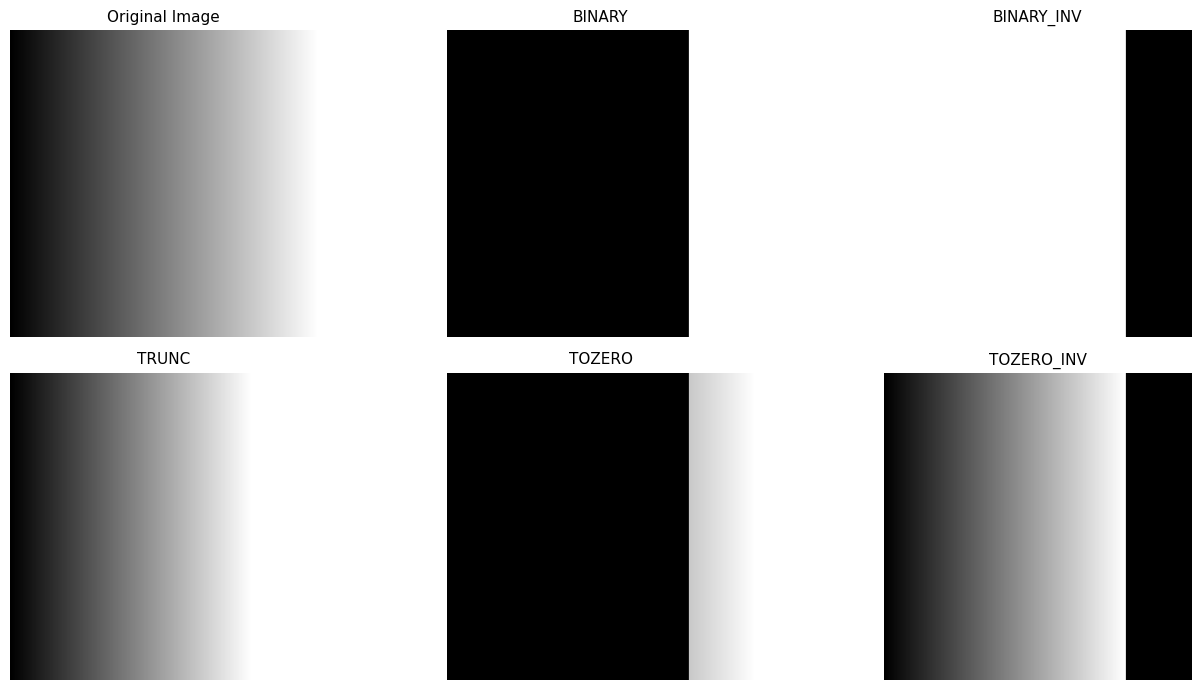

Nilai ambang          : 200
Piksel > 200        : 14080 dari 65536 (21.5%)
  BINARY      nilai unik=  2  rata-rata=  54.8  hitam= 78.5%  putih= 21.5%
  BINARY_INV  nilai unik=  2  rata-rata= 200.2  hitam= 21.5%  putih= 78.5%
  TRUNC       nilai unik=201  rata-rata= 121.5  hitam=  0.4%  putih=  0.0%
  TOZERO      nilai unik= 56  rata-rata=  49.0  hitam= 78.5%  putih=  0.4%
  TOZERO_INV  nilai unik=201  rata-rata=  78.5  hitam= 21.9%  putih=  0.0%


In [6]:
def threshold_manual(citra, thresh, jenis, maxval=255):
    """Thresholding global manual dengan operasi boolean NumPy.

    Args:
        citra (np.ndarray): citra grayscale.
        thresh (int): nilai ambang.
        jenis (str): BINARY, BINARY_INV, TRUNC, TOZERO, atau TOZERO_INV.
        maxval (int): nilai maksimal yang dipakai jenis BINARY/BINARY_INV.

    Returns:
        np.ndarray: citra hasil thresholding bertipe uint8.
    """
    citra = citra.astype(np.int32)
    di_atas = citra > thresh          # mask boolean: True bila piksel > thresh

    if jenis == 'BINARY':
        hasil = np.where(di_atas, maxval, 0)
    elif jenis == 'BINARY_INV':
        hasil = np.where(di_atas, 0, maxval)
    elif jenis == 'TRUNC':
        hasil = np.where(di_atas, thresh, citra)
    elif jenis == 'TOZERO':
        hasil = np.where(di_atas, citra, 0)
    elif jenis == 'TOZERO_INV':
        hasil = np.where(di_atas, 0, citra)
    else:
        raise ValueError(f'jenis threshold tidak dikenal: {jenis}')

    return np.clip(hasil, 0, 255).astype(np.uint8)


THRESH = 200
JENIS_GLOBAL = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']

hasil_global = [threshold_manual(gradient, THRESH, jenis) for jenis in JENIS_GLOBAL]

tampilkan_citra(
    [gradient] + hasil_global,
    ['Original Image'] + JENIS_GLOBAL,
    cmap='gray', figsize=(14, 7), baris=2,
)

print(f'Nilai ambang          : {THRESH}')
print(f'Piksel > {THRESH}        : {int((gradient > THRESH).sum())} dari {gradient.size} '
      f'({100 * (gradient > THRESH).mean():.1f}%)')
for jenis, hasil in zip(JENIS_GLOBAL, hasil_global):
    print(f'  {jenis:11s} nilai unik={len(np.unique(hasil)):3d}  '
          f'rata-rata={hasil.mean():6.1f}  hitam={100 * (hasil == 0).mean():5.1f}%  '
          f'putih={100 * (hasil == 255).mean():5.1f}%')

**Pembacaan hasil.** Karena citra uji berupa gradient yang naik dari 0 ke 255,
ambang `T = 200` membagi citra menjadi dua daerah: sekitar 21% piksel di
sebelah kanan berada di atas ambang, sisanya di bawah ambang.

- `BINARY` hanya menyisakan daerah terang sebagai putih, sedangkan sisanya hitam.
- `BINARY_INV` adalah kebalikannya, sehingga daerah gelap yang menjadi putih.
- `TRUNC` tidak mengubah piksel gelap, tetapi semua piksel terang dipangkas tepat
  pada nilai 200. Akibatnya bagian terang menjadi rata dan jumlah nilai uniknya
  menyusut.
- `TOZERO` mempertahankan piksel terang apa adanya dan menghapus piksel gelap,
  sehingga hanya bagian terang yang tersisa di atas latar hitam.
- `TOZERO_INV` mempertahankan piksel gelap dan menghapus piksel terang.

Perhatikan bahwa hanya `BINARY` dan `BINARY_INV` yang menghasilkan citra biner
murni (hanya bernilai 0 dan 255). Ketiga jenis lainnya tetap mempertahankan
informasi keabuan asli pada salah satu sisi ambang, sesuai tabel ketentuan.

---

## 2. Adaptive Threshold secara Manual (Tugas 4)

Citra sudoku pada folder aset difoto dengan pencahayaan yang tidak merata:
bagian kiri jauh lebih gelap daripada bagian kanan. Kondisi ini membuat
thresholding global gagal. Ambang tetap 127 memang cocok untuk sisi kanan,
tetapi memaksa seluruh sisi kiri menjadi hitam karena nilai intensitasnya
memang berada di bawah 127 di mana-mana.

Thresholding adaptif menyelesaikan masalah tersebut dengan memberi **setiap
piksel ambangnya sendiri** yang dihitung dari lingkungan sekitarnya:

$$T(x, y) = \text{rata-rata lokal}(x, y) - C$$

Nilai `T(x, y)` dihitung dari jendela berukuran `b × b` yang berpusat di piksel
`(x, y)`. Piksel dibandingkan dengan keadaan lokalnya, bukan dengan nilai
global, sehingga piksel yang lebih terang daripada lingkungannya menjadi putih
walaupun nilai absolutnya berbeda di bagian citra yang lain.

Dua hal yang memengaruhi hasil:

- **Ukuran blok `b`** (harus ganjil). Jendela harus sedikit lebih besar daripada
  goresan objek yang ingin dipertahankan. Pada citra sudoku ini lebar goresan
  angka sekitar 10 piksel, sehingga `b = 11` sudah memadai. Blok terlalu kecil
  membuat hasil berbintik, sedangkan blok terlalu besar membuat perilakunya
  kembali mendekati threshold global.
- **Konstanta `C`**. Nilai ini dikurangkan dari rata-rata lokal sehingga ambang
  menjadi lebih rendah. Pada area homogen (latar polos) `C` yang terlalu kecil
  membuat hasil penuh bintik karena nilai piksel berfluktuasi di sekitar
  rata-ratanya sendiri.

Praktikum ini memakai `b = 11`, `C = 2`, dan `sigma = 2` untuk jendela Gaussian,
serta membandingkannya dengan threshold global manual pada ambang 127. Sesuai
ketentuan, `cv.threshold()`, `cv.adaptiveThreshold()`, dan fungsi filter siap
pakai tidak dipakai untuk menghasilkan citra di bawah ini. Rata-rata lokal
dihitung dengan konvolusi yang ditulis sendiri: kernel rata-rata untuk varian
*mean*, dan kernel Gaussian 2D untuk varian *Gaussian*.

In [7]:
def konvolusi_manual(citra, kernel, mode_tepi='edge'):
    """Konvolusi 2D manual tanpa cv.filter2D() maupun scipy.

    Setiap koefisien kernel digeser ke seluruh posisi citra, dikalikan dengan
    citra yang sudah diberi padding, lalu dijumlahkan.

    Args:
        citra (np.ndarray): citra grayscale.
        kernel (np.ndarray): kernel 2D berukuran ganjil.
        mode_tepi (str): cara mengisi tepi, 'edge' meniru perilaku OpenCV.

    Returns:
        np.ndarray: hasil konvolusi bertipe float64.
    """
    citra = citra.astype(np.float64)
    tinggi, lebar = citra.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2

    padded = np.pad(citra, ((ph, ph), (pw, pw)), mode=mode_tepi)
    hasil = np.zeros((tinggi, lebar), dtype=np.float64)
    for i in range(kh):
        for j in range(kw):
            hasil += kernel[i, j] * padded[i:i + tinggi, j:j + lebar]
    return hasil


def kernel_rata(ukuran):
    """Kernel rata-rata ukuran x ukuran untuk ADAPTIVE_THRESH_MEAN_C."""
    return np.full((ukuran, ukuran), 1.0 / (ukuran * ukuran))


def kernel_gaussian(ukuran, sigma):
    """Kernel Gaussian 2D yang dinormalkan untuk ADAPTIVE_THRESH_GAUSSIAN_C.

    Piksel yang dekat dengan pusat jendela mendapat bobot lebih besar,
    sehingga rata-rata lokal lebih mengikuti keadaan di sekitar piksel itu.
    """
    sumbu = np.arange(ukuran) - (ukuran - 1) / 2.0
    xx, yy = np.meshgrid(sumbu, sumbu)
    bobot = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    return bobot / bobot.sum()


def adaptive_manual(citra, jenis='mean', blok=11, C=2, sigma=2.0, maxval=255):
    """Thresholding adaptif manual.

    Langkahnya: hitung rata-rata lokal dengan konvolusi, kurangi dengan C untuk
    memperoleh ambang lokal T(x, y), lalu bandingkan tiap piksel dengan
    ambangnya sendiri.

    Args:
        citra (np.ndarray): citra grayscale.
        jenis (str): 'mean' atau 'gaussian'.
        blok (int): ukuran jendela (harus ganjil).
        C (int): konstanta yang dikurangkan dari rata-rata lokal.
        sigma (float): simpangan baku kernel Gaussian.
        maxval (int): nilai untuk piksel yang dianggap putih.

    Returns:
        np.ndarray: citra biner hasil thresholding adaptif.
    """
    if blok % 2 == 0:
        raise ValueError('ukuran blok harus ganjil')

    if jenis == 'mean':
        kernel = kernel_rata(blok)
    elif jenis == 'gaussian':
        kernel = kernel_gaussian(blok, sigma)
    else:
        raise ValueError("jenis harus 'mean' atau 'gaussian'")

    rata_lokal = konvolusi_manual(citra, kernel)

    # Dibulatkan ke bilangan bulat karena ambang lokal pada OpenCV disimpan
    # sebagai citra 8-bit sebelum dibandingkan dengan nilai piksel.
    rata_lokal = np.round(rata_lokal).astype(np.int32)
    ambang_lokal = rata_lokal - C

    return np.where(citra.astype(np.int32) > ambang_lokal, maxval, 0).astype(np.uint8)

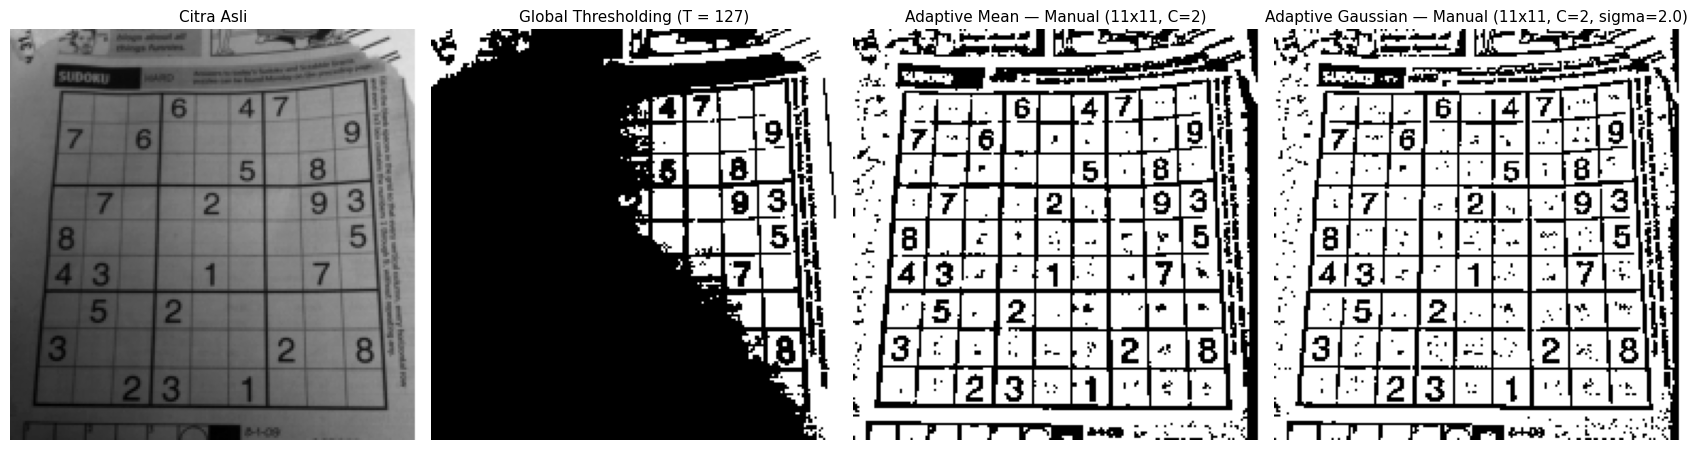

Jendela 11x11, C=2, sigma=2.0
Piksel putih pada global   :  25.0%
Piksel putih pada adaptif mean  :  71.5%
Piksel putih pada adaptif gaussian:  73.9%


In [8]:
BLOK, C, SIGMA = 11, 2, 2.0

global_sudoku = threshold_manual(sudoku_gray, 127, 'BINARY')
adaptif_mean  = adaptive_manual(sudoku_gray, 'mean', blok=BLOK, C=C)
adaptif_gauss = adaptive_manual(sudoku_gray, 'gaussian', blok=BLOK, C=C, sigma=SIGMA)

tampilkan_citra(
    [sudoku_gray, global_sudoku, adaptif_mean, adaptif_gauss],
    ['Citra Asli',
     'Global Thresholding (T = 127)',
     f'Adaptive Mean — Manual ({BLOK}x{BLOK}, C={C})',
     f'Adaptive Gaussian — Manual ({BLOK}x{BLOK}, C={C}, sigma={SIGMA})'],
    cmap='gray', figsize=(17, 5),
)

print(f'Jendela {BLOK}x{BLOK}, C={C}, sigma={SIGMA}')
print(f'Piksel putih pada global   : {100 * (global_sudoku > 0).mean():5.1f}%')
print(f'Piksel putih pada adaptif mean  : {100 * (adaptif_mean > 0).mean():5.1f}%')
print(f'Piksel putih pada adaptif gaussian: {100 * (adaptif_gauss > 0).mean():5.1f}%')

In [9]:
# Pemeriksaan silang (bukan bagian dari implementasi):
# hasil manual dibandingkan dengan cv.adaptiveThreshold() untuk memastikan
# perhitungan rata-rata lokal dan aturan pembandingan sudah benar.
pembanding_mean = cv.adaptiveThreshold(
    sudoku_gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, BLOK, C)
pembanding_gauss = cv.adaptiveThreshold(
    sudoku_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, BLOK, C)

for nama, hasil_manual, hasil_pustaka in [('mean', adaptif_mean, pembanding_mean),
                                          ('gaussian', adaptif_gauss, pembanding_gauss)]:
    beda = int((hasil_manual != hasil_pustaka).sum())
    print(f'adaptive {nama:8s}: {beda} piksel berbeda dari OpenCV '
          f'({100 * beda / hasil_manual.size:.3f}% dari {hasil_manual.size} piksel)')

adaptive mean    : 0 piksel berbeda dari OpenCV (0.000% dari 36863 piksel)
adaptive gaussian: 0 piksel berbeda dari OpenCV (0.000% dari 36863 piksel)


**Pembacaan hasil.** Perbedaan ketiga panel sangat jelas:

- **Global threshold (T = 127)** hanya menyisakan sisi kanan citra. Seluruh
  bagian kiri yang lebih gelap menjadi hitam rata karena nilai intensitasnya
  tidak pernah melewati 127. Kotak sudoku di sisi kiri hilang sama sekali.
- **Adaptive mean** berhasil memunculkan kembali garis kotak dan angka pada
  kedua sisi citra. Setiap piksel dibandingkan dengan rata-rata jendela
  `11 × 11` di sekitarnya, sehingga kemiringan pencahayaan antarwilayah tidak
  lagi menjadi masalah.
- **Adaptive Gaussian** memberi hasil yang paling bersih. Bobot Gaussian membuat
  piksel di pusat jendela lebih berpengaruh, sehingga ambang lokal lebih setia
  pada keadaan tepat di sekitar piksel dan bintik noise pada area homogen
  berkurang dibandingkan varian *mean*.

Pemeriksaan silang menunjukkan hasil manual **identik** dengan
`cv.adaptiveThreshold()` untuk kedua varian. Kunci kecocokan tersebut adalah
pembulatan rata-rata lokal ke bilangan bulat sebelum dibandingkan, karena
OpenCV menyimpan rata-rata lokal sebagai citra 8-bit. Tanpa pembulatan, terdapat
ratusan piksel yang berbeda tepat pada nilai yang berada di perbatasan ambang.

Kedua varian adaptif tetap menyisakan sedikit noise pada area kertas di luar
kotak sudoku. Ini adalah konsekuensi wajar dari `C` yang kecil: pada area
homogen, fluktuasi nilai piksel di sekitar rata-ratanya sendiri sudah cukup
untuk melewati ambang. Menaikkan `C` akan membersihkan area tersebut, tetapi
risikannya angka tipis yang kontrasnya rendah ikut hilang.

---

## 3. Otsu Thresholding Manual (Tugas 5)

### 3.1 Dasar Perhitungan

Otsu memilih nilai ambang secara otomatis dengan cara memaksimalkan **variansi
antar-kelas** (*between-class variance*) sekaligus meminimalkan variansi
dalam-kelas. Untuk setiap nilai ambang `t` yang mungkin, histogram dibagi
menjadi dua kelas: latar `0 … t` dan objek `t+1 … 255`. Setiap kelas memiliki
bobot (`w`) dan rata-rata (`mu`), sehingga

$$\sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,[\mu_0(t) - \mu_1(t)]^2$$

Nilai `t` yang menghasilkan `sigma_B^2` terbesar menjadi ambang terpilih.
Perhitungan dilakukan untuk seluruh 256 nilai `t` dengan memanfaatkan
histogram kumulatif, sehingga jauh lebih cepat daripada menghitung ulang
rata-rata tiap kelas dari awal.

In [10]:
def otsu_manual(gray):
    """Otsu thresholding manual tanpa pustaka.

    Menghitung variansi antar-kelas untuk setiap nilai ambang yang mungkin,
    lalu mengembalikan nilai ambang dengan variansi terbesar.

    Args:
        gray (np.ndarray): citra grayscale.

    Returns:
        int: nilai ambang hasil Otsu.
    """
    gray = gray.astype(np.uint8)
    jumlah_piksel = gray.size

    # Histogram dan probabilitas tiap tingkat keabuan
    histogram = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    probabilitas = histogram / jumlah_piksel
    intensitas = np.arange(256)

    # Jumlah kumulatif: bobot kelas latar w0(t) dan mu0(t) * w0(t)
    bobot_kumulatif = np.cumsum(probabilitas)
    rerata_kumulatif = np.cumsum(probabilitas * intensitas)
    rerata_total = rerata_kumulatif[-1]

    thresh_terbaik = 0
    variansi_terbaik = -1.0

    for t in range(256):
        w0 = bobot_kumulatif[t]          # bobot kelas latar
        w1 = 1.0 - w0                    # bobot kelas objek
        if w0 <= 0 or w1 <= 0:           # salah satu kelas kosong, lewati
            continue

        mu0 = rerata_kumulatif[t] / w0
        mu1 = (rerata_total - rerata_kumulatif[t]) / w1

        variansi_antar = w0 * w1 * (mu0 - mu1) ** 2
        if variansi_antar > variansi_terbaik:
            variansi_terbaik = variansi_antar
            thresh_terbaik = t

    return thresh_terbaik

Rentang intensitas Lena            : 5 - 255
Otsu manual                        : v = 113
Otsu pustaka (cv.THRESH_OTSU)      : v = 113
Selisih kedua nilai ambang         : 0


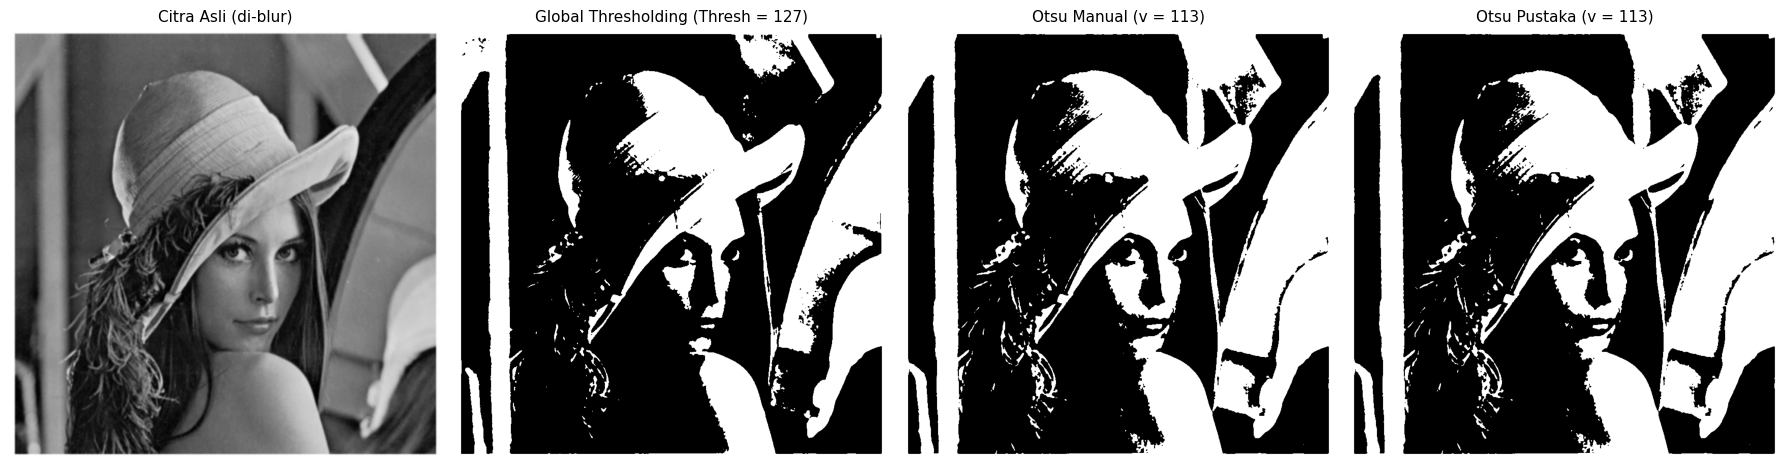

In [11]:
# Citra Lena dihaluskan lebih dulu agar noise tidak ikut terhitung pada histogram
lena_blur = cv.GaussianBlur(lena_gray, (5, 5), 0)
THRESH_GLOBAL = 127

t_otsu_manual = otsu_manual(lena_blur)
t_otsu_pustaka, _ = cv.threshold(lena_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
t_otsu_pustaka = int(t_otsu_pustaka)

biner_global      = threshold_manual(lena_blur, THRESH_GLOBAL, 'BINARY')
biner_otsu_manual = threshold_manual(lena_blur, t_otsu_manual, 'BINARY')
biner_otsu_pustaka = threshold_manual(lena_blur, t_otsu_pustaka, 'BINARY')

print(f'Rentang intensitas Lena            : {lena_blur.min()} - {lena_blur.max()}')
print(f"Otsu manual                        : v = {t_otsu_manual}")
print(f"Otsu pustaka (cv.THRESH_OTSU)      : v = {t_otsu_pustaka}")
print(f'Selisih kedua nilai ambang         : {abs(t_otsu_manual - t_otsu_pustaka)}')

tampilkan_citra(
    [lena_blur, biner_global, biner_otsu_manual, biner_otsu_pustaka],
    ['Citra Asli (di-blur)',
     f'Global Thresholding (Thresh = {THRESH_GLOBAL})',
     f"Otsu Manual (v = {t_otsu_manual})",
     f"Otsu Pustaka (v = {t_otsu_pustaka})"],
    cmap='gray', figsize=(18, 5),
)

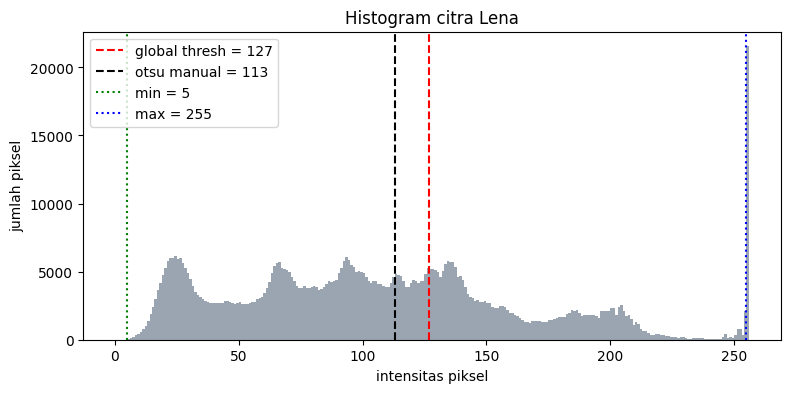

In [12]:
# Histogram citra Lena beserta posisi ambang global dan ambang Otsu
plt.figure(figsize=(9, 4))
plt.hist(lena_blur.ravel(), bins=256, range=(0, 256), color='#9aa5b1')
plt.axvline(THRESH_GLOBAL, color='red', linestyle='--',
            label=f'global thresh = {THRESH_GLOBAL}')
plt.axvline(t_otsu_manual, color='black', linestyle='--',
            label=f'otsu manual = {t_otsu_manual}')
plt.axvline(lena_blur.min(), color='green', linestyle=':', label=f'min = {lena_blur.min()}')
plt.axvline(lena_blur.max(), color='blue', linestyle=':', label=f'max = {lena_blur.max()}')
plt.title('Histogram citra Lena')
plt.xlabel('intensitas piksel')
plt.ylabel('jumlah piksel')
plt.legend()
plt.show()

### 3.2 Mengapa Binary Threshold Bisa Hitam Seluruhnya?

Pertanyaan pada modul menyangkut citra `lena_gs_lc2`, yaitu versi Lena dengan
kontras rendah yang rentang intensitasnya hanya 85–108. Agar kasus tersebut
dapat ditelusuri apa pun versi berkas yang ada di folder Drive, sel di bawah ini
memeriksa rentang intensitas citra yang dimuat. Bila rentangnya masih lebar,
intensitas citra dipetakan ke rentang 85–108 supaya kondisinya setara dengan
citra pada modul.

Citra uji        : hasil pemetaan intensitas citra asli ke rentang 85-108
Rentang intensitas : 85 - 108
Nilai tengah       : 96
Otsu manual        : v = 94
Piksel > 127 pada citra ini : 0
Ambang yang membuat citra masih terlihat : 86 sampai 107


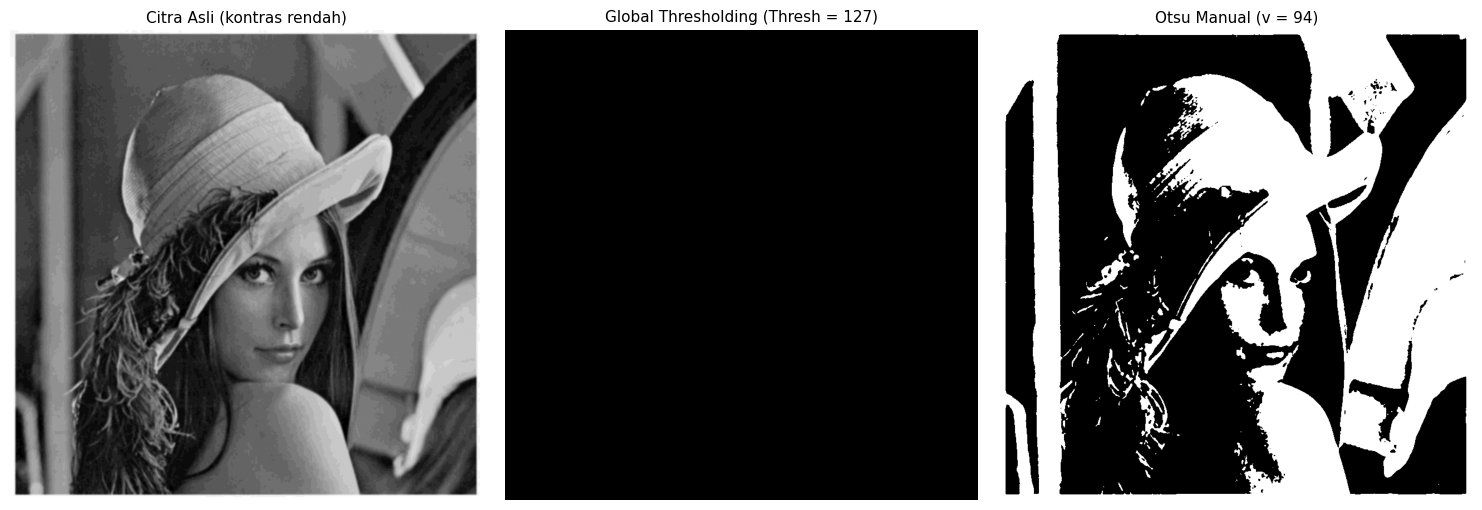

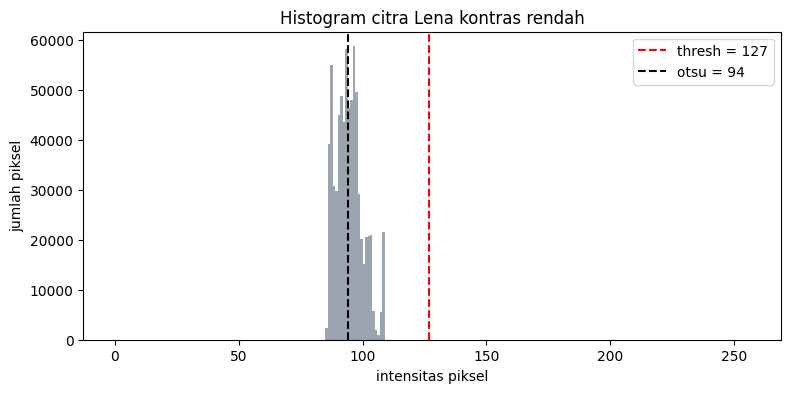

In [13]:
rentang = int(lena_blur.max()) - int(lena_blur.min())

if rentang > 40:
    lena_kontras_rendah = np.clip(
        85 + lena_blur.astype(np.float64) / 255.0 * (108 - 85), 0, 255).astype(np.uint8)
    keterangan = 'hasil pemetaan intensitas citra asli ke rentang 85-108'
else:
    lena_kontras_rendah = lena_blur.copy()
    keterangan = 'citra asli yang memang sudah berentang sempit'

t_otsu_lc = otsu_manual(lena_kontras_rendah)
biner_global_lc = threshold_manual(lena_kontras_rendah, THRESH_GLOBAL, 'BINARY')
biner_otsu_lc   = threshold_manual(lena_kontras_rendah, t_otsu_lc, 'BINARY')

print(f'Citra uji        : {keterangan}')
print(f'Rentang intensitas : {lena_kontras_rendah.min()} - {lena_kontras_rendah.max()}')
print(f'Nilai tengah       : {(int(lena_kontras_rendah.min()) + int(lena_kontras_rendah.max())) // 2}')
print(f'Otsu manual        : v = {t_otsu_lc}')
print(f'Piksel > {THRESH_GLOBAL} pada citra ini : {int((lena_kontras_rendah > THRESH_GLOBAL).sum())}')
print(f'Ambang yang membuat citra masih terlihat : {lena_kontras_rendah.min() + 1} '
      f'sampai {lena_kontras_rendah.max() - 1}')

tampilkan_citra(
    [lena_kontras_rendah, biner_global_lc, biner_otsu_lc],
    ['Citra Asli (kontras rendah)',
     f'Global Thresholding (Thresh = {THRESH_GLOBAL})',
     f"Otsu Manual (v = {t_otsu_lc})"],
    cmap='gray', figsize=(15, 5),
)

plt.figure(figsize=(9, 4))
plt.hist(lena_kontras_rendah.ravel(), bins=256, range=(0, 256), color='#9aa5b1')
plt.axvline(THRESH_GLOBAL, color='red', linestyle='--', label=f'thresh = {THRESH_GLOBAL}')
plt.axvline(t_otsu_lc, color='black', linestyle='--', label=f"otsu = {t_otsu_lc}")
plt.title('Histogram citra Lena kontras rendah')
plt.xlabel('intensitas piksel')
plt.ylabel('jumlah piksel')
plt.legend()
plt.show()

**Jawaban.** Hasil binary thresholding menjadi hitam seluruhnya karena
**seluruh nilai intensitas citra berada di bawah nilai ambang yang dipakai**.
Citra Lena kontras rendah hanya memakai rentang 85–108, sedangkan ambangnya
127. Aturan `BINARY` menyatakan piksel diubah menjadi 255 hanya jika nilainya
`> 127`; karena tidak ada satu pun piksel yang melewati 127, semua piksel jatuh
ke kondisi "selain itu" dan diubah menjadi 0.

Histogram di atas memperlihatkan alasannya secara langsung: seluruh distribusi
intensitas menumpuk di antara 85 dan 108, yaitu **di sebelah kiri garis merah
127**. Tidak ada satu pun batang histogram yang menyentuh atau melewati garis
tersebut, sehingga hasil thresholdnya kosong.

Agar citra Lena masih terlihat, ambang harus diletakkan **di dalam rentang
intensitasnya sendiri**, yaitu antara 85 dan 108 (bukan tepat pada batasnya,
supaya kedua kelas tetap terisi). Nilai Otsu yang dihitung dari histogram
secara otomatis berada di wilayah ini; pada percobaan di atas diperoleh
`v = 94`. Nilai lain seperti 92 atau 100 juga masih memisahkan rambut yang gelap
dari wajah dan topi yang lebih terang. Sebaliknya, ambang 127 — yang ditetapkan
tanpa melihat histogram — berada jauh di luar rentang tersebut sehingga tidak
berguna sama sekali.

Kesimpulannya, threshold global hanya bekerja bila nilai ambangnya dipilih
berdasarkan histogram citra. Metode Otsu melakukan hal itu secara otomatis,
itulah sebabnya Otsu jauh lebih andal untuk citra berkontras rendah.

### 3.3 Pembanding: Otsu pada Citra KTP (Tugas 5B)

Citra KTP memiliki karakteristik yang berlawanan dengan Lena kontras rendah:
rentang intensitasnya lebar karena memuat teks hitam pekat di atas latar biru
muda yang terang. Perbandingan ini memperlihatkan bagaimana perilaku kedua
metode berubah ketika histogram benar-benar terpisah menjadi dua kelompok.

Rentang intensitas KTP        : 16 - 255
Otsu manual                   : v = 165
Otsu pustaka                  : v = 165
Piksel > 127 (global) : 88.5%
Piksel > 165 (otsu)   : 84.4%


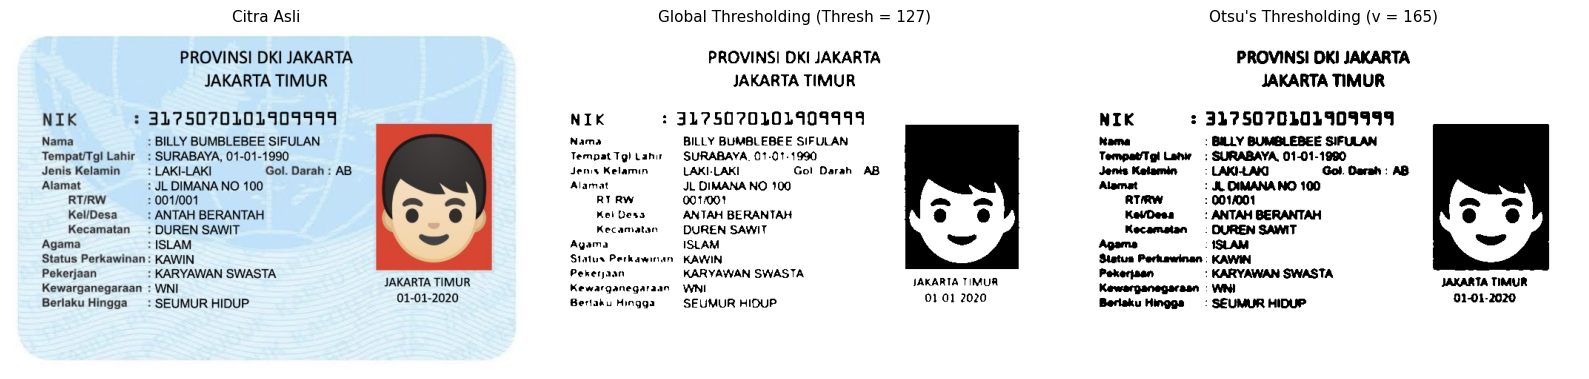

In [14]:
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)

t_otsu_ktp = otsu_manual(ktp_blur)
biner_global_ktp = threshold_manual(ktp_blur, THRESH_GLOBAL, 'BINARY')
biner_otsu_ktp   = threshold_manual(ktp_blur, t_otsu_ktp, 'BINARY')

print(f'Rentang intensitas KTP        : {ktp_blur.min()} - {ktp_blur.max()}')
print(f"Otsu manual                   : v = {t_otsu_ktp}")
print(f"Otsu pustaka                  : v = {int(cv.threshold(ktp_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[0])}")
print(f'Piksel > {THRESH_GLOBAL} (global) : {100 * (ktp_blur > THRESH_GLOBAL).mean():.1f}%')
print(f'Piksel > {t_otsu_ktp} (otsu)   : {100 * (ktp_blur > t_otsu_ktp).mean():.1f}%')

tampilkan_citra(
    [bgr2rgb(ktp_bgr), biner_global_ktp, biner_otsu_ktp],
    ['Citra Asli',
     f'Global Thresholding (Thresh = {THRESH_GLOBAL})',
     f"Otsu's Thresholding (v = {t_otsu_ktp})"],
    cmap=[None, 'gray', 'gray'], figsize=(16, 5),
)

**Pembacaan hasil.** Pada citra KTP, ambang 127 dan ambang Otsu sama-sama
menghasilkan citra yang masih terbaca. Perbedaannya terletak pada ketepatan
pemisahan:

- Ambang global 127 berada di bawah nilai Otsu, sehingga lebih banyak piksel
  latar yang ikut menjadi putih. Teks tetap terbaca, tetapi latar berwatermark
  dan area foto ikut memutih sehingga muncul noise yang tidak perlu.
- Otsu memilih ambang yang lebih tinggi karena histogram KTP benar-benar
  bimodal: satu puncak besar dari latar biru terang dan satu kelompok dari teks
  hitam. Ambang tersebut memisahkan keduanya dengan lebih rapi, sehingga teks
  tercetak lebih tegas dan latar lebih bersih.

Kesimpulannya, threshold global hanya bermasalah ketika ambangnya berada di luar
rentang intensitas citra (kasus Lena kontras rendah). Untuk citra yang
histogramnya terpisah jelas seperti KTP, ambang global sederhana pun masih
bekerja, dan Otsu memberikan hasil yang lebih terarah karena ambangnya dihitung
dari data, bukan ditetapkan tetap.

---

## 4. Segmentasi Berbasis Wilayah (Tugas 6)

Thresholding bertanya "apakah nilai piksel ini di atas atau di bawah ambang?".
Segmentasi berbasis wilayah bertanya hal yang berbeda: **"apakah piksel ini
mirip dengan tetangga-tetangganya?"** Citra dibagi menjadi beberapa wilayah yang
masing-masing terdiri atas piksel-piksel yang saling berdekatan dan memiliki
karakteristik serupa.

### 4.1 Region Growing Manual (Tugas 6A)

Region growing dimulai dari satu titik awal (*seed*). Region lalu tumbuh ke
tetangga (4 atau 8 ketetanggaan) selama kriteria kesamaan terpenuhi. Kriteria
yang dipakai di sini adalah perbedaan intensitas terhadap rata-rata region:

$$|I(q) - \mu_{\text{region}}| < T$$

Pertumbuhan berhenti ketika tidak ada lagi tetangga yang memenuhi kriteria.
Citra `coin.ppm` cocok untuk memperlihatkan perilaku ini: objeknya jelas (koin),
latarnya cukup homogen, dan beberapa koin saling bersentuhan.

Tiga seed diuji, masing-masing dengan tiga nilai `T`:

| Seed | Koordinat (baris, kolom) | Posisi |
|------|--------------------------|--------|
| Dalam koin | `(35, 45)` | di tengah salah satu koin |
| Di latar | `(150, 45)` | pada latar gelap di antara baris koin |
| Di tepi koin | `(35, 271)` | tepat pada batas antara koin dan latar |

Hasilnya ditampilkan sebagai grid dengan **satu baris per seed**. Kolom pertama
memperlihatkan citra asli beserta penanda posisi seed (tanda `+` merah),
sedangkan tiga kolom berikutnya memperlihatkan region hasil pertumbuhan untuk
`T = 5`, `20`, dan `60`. Region yang terdeteksi ditandai dengan **warna merah**
di atas citra asli, sehingga luas dan sebarannya langsung terlihat.

In [15]:
def region_growing(citra, seed, T, konektivitas=8):
    """Region growing manual dari sebuah seed.

    Piksel tetangga dimasukkan ke dalam region bila selisih intensitasnya
    terhadap rata-rata region masih lebih kecil dari T.

    Args:
        citra (np.ndarray): citra grayscale.
        seed (tuple): titik awal (baris, kolom).
        T (int): ambang kesamaan intensitas.
        konektivitas (int): 4 atau 8 ketetanggaan.

    Returns:
        np.ndarray: mask boolean region hasil pertumbuhan.
    """
    tinggi, lebar = citra.shape
    mask = np.zeros((tinggi, lebar), dtype=bool)

    baris, kolom = seed
    mask[baris, kolom] = True
    jumlah = 1
    total = float(citra[baris, kolom])

    arah = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    if konektivitas == 8:
        arah += [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    tumpukan = deque([(baris, kolom)])
    while tumpukan:
        r, c = tumpukan.popleft()
        rata_region = total / jumlah
        for dr, dc in arah:
            nr, nc = r + dr, c + dc
            if 0 <= nr < tinggi and 0 <= nc < lebar and not mask[nr, nc]:
                if abs(float(citra[nr, nc]) - rata_region) < T:
                    mask[nr, nc] = True
                    jumlah += 1
                    total += float(citra[nr, nc])
                    tumpukan.append((nr, nc))

    return mask


def tampilkan_hasil_region(citra, seeds, nilai, fungsi_region, label_nilai,
                           judul, warna=(1.0, 0.0, 0.0, 0.75)):
    """Menampilkan grid hasil segmentasi berbasis wilayah.

    Kolom pertama berisi citra asli beserta penanda posisi seed, kolom
    berikutnya berisi hasil segmentasi untuk setiap nilai parameter.

    Args:
        citra (np.ndarray): citra grayscale.
        seeds (list): daftar pasangan (nama seed, (baris, kolom)).
        nilai (list): daftar nilai parameter yang diuji.
        fungsi_region (callable): fungsi(seed, nilai) -> mask boolean.
        label_nilai (str): nama parameter, misalnya 'T' atau 'toleransi'.
        judul (str): judul metode yang ditampilkan pada setiap panel.
        warna (tuple): warna RGBA untuk menandai region yang terdeteksi.
    """
    jumlah_kolom = len(nilai) + 1
    fig, axes = plt.subplots(len(seeds), jumlah_kolom,
                             figsize=(4.3 * jumlah_kolom, 3.9 * len(seeds)))
    axes = np.atleast_2d(axes)

    for i, (nama_seed, seed) in enumerate(seeds):
        # Kolom pertama: citra asli dengan penanda posisi seed
        ax = axes[i, 0]
        ax.imshow(citra, cmap='gray')
        ax.plot(seed[1], seed[0], marker='+', color='red',
                markersize=15, markeredgewidth=2.5)
        ax.set_title(f'Citra asli + seed\n{nama_seed} {seed}', fontsize=10)
        ax.axis('off')

        # Kolom berikutnya: region hasil segmentasi ditandai warna merah
        for j, n in enumerate(nilai, start=1):
            mask = fungsi_region(seed, n)

            ax = axes[i, j]
            ax.imshow(citra, cmap='gray')

            lapisan = np.zeros((*citra.shape, 4))
            lapisan[mask] = warna
            ax.imshow(lapisan)

            ax.set_title(f'{judul}, {label_nilai} = {n}\n{mask.sum()} piksel', fontsize=10)
            ax.axis('off')

    plt.tight_layout()
    plt.show()

Ukuran citra coin : (303, 384) | rentang intensitas: 1 - 252


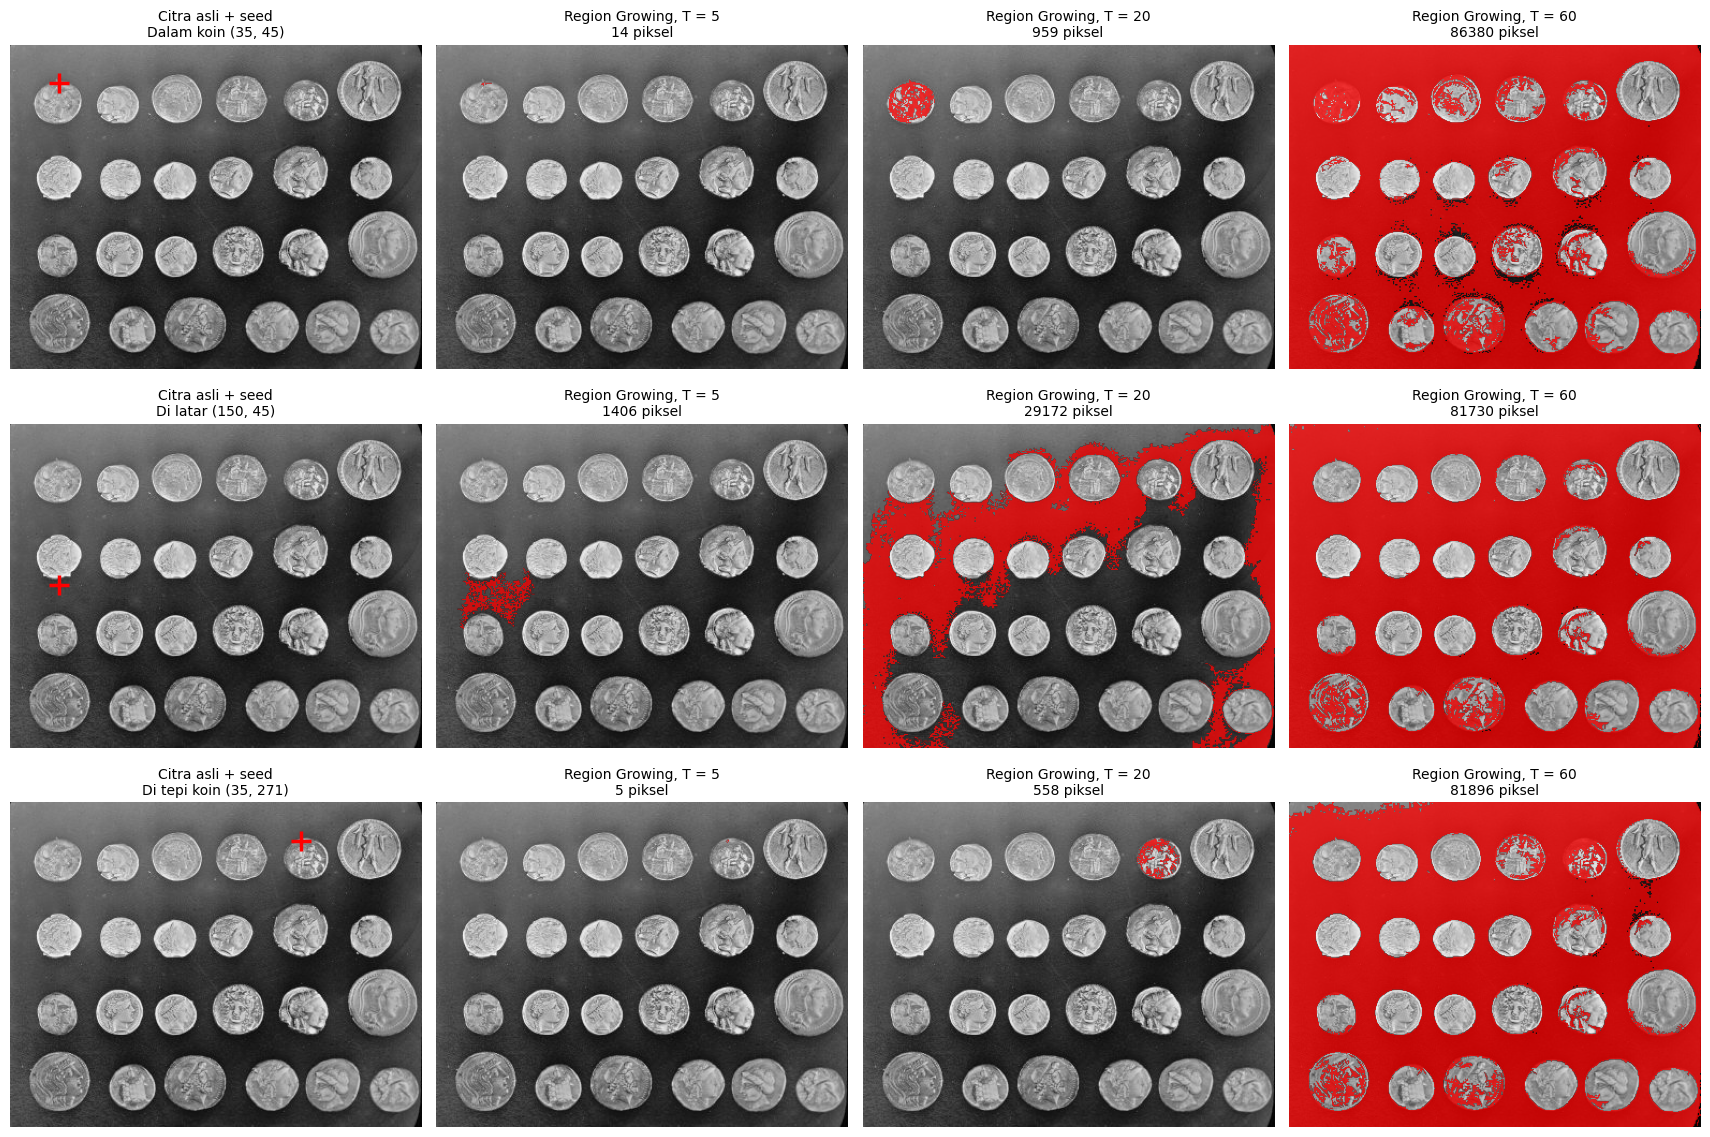

Seed            nilai seed         T=5        T=20        T=60
Dalam koin             154          14         959       86380
Di latar                62        1406       29172       81730
Di tepi koin           152           5         558       81896


In [16]:
print('Ukuran citra coin :', coin.shape, '| rentang intensitas:', coin.min(), '-', coin.max())

# Koordinat seed mengikuti contoh pada modul untuk citra 303 x 384 piksel.
# Bila ukuran citra berbeda, koordinatnya diskalakan agar tetap menunjuk posisi
# yang sama, sehingga seed tidak jatuh di tempat yang salah.
SKALA = (coin.shape[0] / 303, coin.shape[1] / 384)


def skala_seed(seed):
    return (int(round(seed[0] * SKALA[0])), int(round(seed[1] * SKALA[1])))


SEEDS = [
    ('Dalam koin',   skala_seed((35, 45))),
    ('Di latar',     skala_seed((150, 45))),
    ('Di tepi koin', skala_seed((35, 271))),
]
NILAI_T = [5, 20, 60]

tampilkan_hasil_region(
    coin, SEEDS, NILAI_T,
    fungsi_region=lambda seed, T: region_growing(coin, seed, T, konektivitas=8),
    label_nilai='T', judul='Region Growing',
)

print(f'{"Seed":14s}{"nilai seed":>12s}' + ''.join(f'{"T=" + str(t):>12s}' for t in NILAI_T))
for nama_seed, seed in SEEDS:
    baris = f'{nama_seed:14s}{int(coin[seed]):>12d}'
    for T in NILAI_T:
        baris += f'{region_growing(coin, seed, T, konektivitas=8).sum():>12d}'
    print(baris)

**Pembacaan hasil.** Tabel di atas mencetak luas region (jumlah piksel) untuk
setiap kombinasi seed dan `T`, sehingga polanya dapat dibaca langsung dari
angkanya. Perhatikan bahwa ketiga baris bergerak dari nilai yang sangat kecil
menuju puluhan ribu piksel ketika `T` dinaikkan.

- **Seed di dalam koin.** Pada `T = 5` region hanya berupa bercak kecil di
  sekitar seed (belasan piksel), karena toleransi terlalu ketat untuk menampung
  variasi tekstur permukaan koin. Pada `T = 20` seluruh permukaan koin ikut
  tumbuh, sehingga masknya menutupi satu koin secara utuh (ratusan piksel). Pada
  `T = 60` region justru "bocor" ke latar dan koin lain sehingga terjadi
  *under-segmentation*: koin yang seharusnya terpisah menyatu menjadi satu
  region besar yang menutupi hampir seluruh citra (puluhan ribu piksel).
- **Seed di latar.** Perilaku serupa muncul pada latar. Pada `T = 5` baru
  sebagian kecil latar di sekitar seed yang terambil, pada `T = 20` region
  meluas mencakup sebagian besar area latar, dan pada `T = 60` hampir seluruh
  citra menjadi satu region. Perhatikan bahwa pada `T` yang sama, region dari
  seed latar jauh lebih luas daripada region dari seed koin, karena latar
  memiliki variasi intensitas yang lebih kecil sehingga lebih mudah menyatu.
- **Seed di tepi koin.** Ini kasus yang paling rapuh. Pada `T = 5` region hampir
  tidak tumbuh sama sekali (hanya beberapa piksel), karena piksel tepat di tepi
  berada pada nilai peralihan sehingga tetangga di kedua sisinya — koin yang
  lebih terang dan latar yang lebih gelap — sama-sama terlalu jauh dari
  rata-rata region. Pada `T = 20` region baru tumbuh menjadi sebagian tepi koin
  dan belum menutupi koin secara utuh. Baru pada `T = 60` region meluas, tetapi
  sudah mencakup latar dan koin sekaligus.

Kesimpulan yang penting: hasil region growing sangat bergantung pada **posisi
seed** dan **nilai T**. Ambang yang terlalu ketat menghasilkan banyak region
kecil (*over-segmentation*), sedangkan ambang yang terlalu longgar membuat objek
berbeda menyatu (*under-segmentation*). Seed yang diletakkan pada piksel tepi
atau piksel noise juga berisiko menggagalkan proses, karena rata-rata region
awalnya belum mewakili objek yang dituju.

### 4.2 Perbandingan dengan `skimage.segmentation.flood()` (Tugas 6B)

`flood()` menyelesaikan pekerjaan yang sama dengan pendekatan yang sedikit
berbeda. Fungsi ini juga menelusuri piksel yang terhubung dari sebuah seed,
tetapi kriterianya memakai **toleransi terhadap nilai seed**, bukan terhadap
rata-rata region yang terus diperbarui. Artinya, selama proses berjalan, nilai
acuan tidak bergeser sedikit pun.

Sel di bawah menjalankan `flood()` pada ketiga seed dan tiga nilai toleransi yang
sama, sehingga hasilnya dapat dibandingkan langsung dengan region growing
manual. Parameter `connectivity=1` berarti 4 ketetanggaan pada citra 2D, dan
region hasilnya ditandai dengan warna merah dengan tata letak grid yang sama.

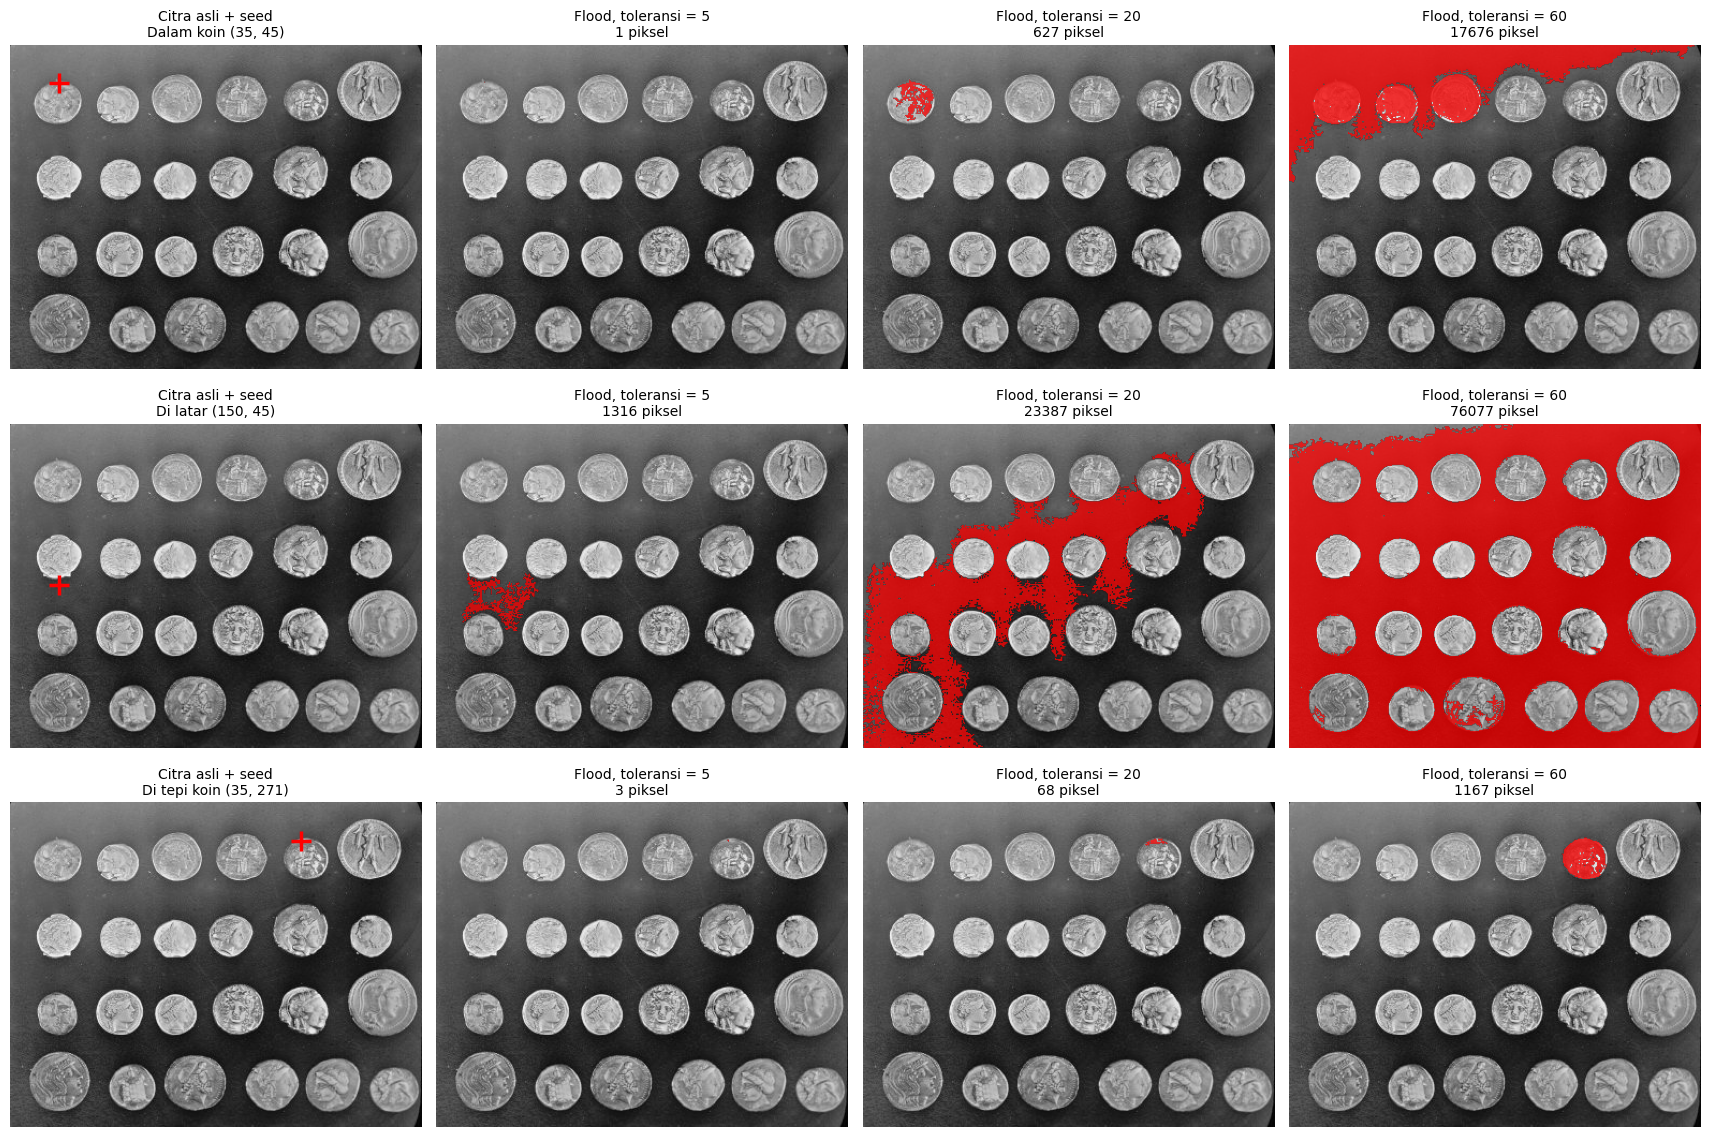

Seed            nilai seed       tol=5      tol=20      tol=60
Dalam koin             154           1         627       17676
Di latar                62        1316       23387       76077
Di tepi koin           152           3          68        1167

Perbandingan luas region (piksel):
Seed            nilai    region growing       flood
Dalam koin          5                14           1
Dalam koin         20               959         627
Dalam koin         60             86380       17676
Di latar            5              1406        1316
Di latar           20             29172       23387
Di latar           60             81730       76077
Di tepi koin        5                 5           3
Di tepi koin       20               558          68
Di tepi koin       60             81896        1167


In [17]:
TOLERANSI = [5, 20, 60]

tampilkan_hasil_region(
    coin, SEEDS, TOLERANSI,
    fungsi_region=lambda seed, tol: flood(coin, seed_point=seed,
                                          tolerance=tol, connectivity=1),
    label_nilai='toleransi', judul='Flood',
)

print(f'{"Seed":14s}{"nilai seed":>12s}' + ''.join(f'{"tol=" + str(t):>12s}' for t in TOLERANSI))
for nama_seed, seed in SEEDS:
    baris = f'{nama_seed:14s}{int(coin[seed]):>12d}'
    for tol in TOLERANSI:
        baris += f'{flood(coin, seed_point=seed, tolerance=tol, connectivity=1).sum():>12d}'
    print(baris)

# Perbandingan langsung luas region kedua metode
print('\nPerbandingan luas region (piksel):')
print(f'{"Seed":14s}{"nilai":>7s}{"region growing":>18s}{"flood":>12s}')
for nama_seed, seed in SEEDS:
    for nilai in NILAI_T:
        a = region_growing(coin, seed, nilai, konektivitas=8).sum()
        b = flood(coin, seed_point=seed, tolerance=nilai, connectivity=1).sum()
        print(f'{nama_seed:14s}{nilai:>7d}{a:>18d}{b:>12d}')

**Pembacaan hasil.** Pola umumnya sama dengan region growing, yaitu toleransi
yang makin longgar menghasilkan region yang makin luas. Namun luasnya tidak
identik, dan arah perbedaannya menarik untuk dicermati.

Pada hampir semua kasus di percobaan ini, region growing justru menghasilkan
region yang **sama atau lebih luas** daripada `flood()` pada nilai yang sama.
Perbedaan paling mencolok muncul pada seed di tepi koin dengan `T = 60`: region
growing meluas menutupi hampir seluruh citra, sedangkan `flood()` hanya
mengambil sebagian kecil area.

Penyebabnya adalah perbedaan **nilai acuan** yang dipakai kedua metode:

- Region growing membandingkan setiap piksel dengan **rata-rata region yang
  terus diperbarui**. Ketika region meluas ke piksel yang agak berbeda, rata-
  ratanya bergeser sedikit demi sedikit, sehingga kriterianya ikut melunak
  secara bertahap. Region dapat "merangkak" melewati perbedaan yang sebenarnya
  cukup besar, dan inilah yang membuat region growing lebih mudah bocor.
- `flood()` membandingkan setiap piksel dengan **nilai seed yang tetap**, tidak
  pernah bergeser. Begitu ada piksel yang selisihnya terhadap nilai seed
  melewati toleransi, piksel itu ditolak dan pertumbuhan berhenti di sana. Pada
  seed di tepi koin, nilai seed adalah nilai peralihan, sehingga koin yang lebih
  terang dan latar yang lebih gelap sama-sama berada di luar toleransi;
  akibatnya region `flood()` terkurung pada jalur sempit bernilai sedang dan
  tidak pernah meluas.

Pada seed di latar, kedua metode memberi luas yang hampir sama. Ini masuk akal
karena latar cukup homogen, sehingga nilai seed sudah mewakili seluruh region
dan rata-rata bergerak tidak memberi keuntungan tambahan.

Kesimpulannya, keduanya sama-sama sangat bergantung pada posisi seed dan besar
toleransi, tetapi wataknya berbeda. `flood()` lebih konservatif dan lebih mudah
diprediksi karena acuannya tidak bergeser, sedangkan region growing dengan
rata-rata bergerak lebih luwes menghadapi objek yang teksturnya bervariasi —
dengan konsekuensi risiko bocor yang lebih besar.

---

## 5. Segmentasi Warna Biru pada KTP (Tugas 7)

Thresholding dan region growing bekerja pada intensitas keabuan. Segmentasi
warna memakai sudut pandang yang berbeda: citra diperlakukan sebagai kumpulan
titik data, dan setiap piksel menjadi satu titik dengan fitur warna. Pendekatan
ini menyelesaikan kasus yang tidak bisa ditangani ambang keabuan, misalnya
memisahkan latar biru KTP dari teks hitam yang sama-sama memiliki intensitas
rendah pada kanal keabuan.

Dua pendekatan dipakai di sini:

1. **K-Means** sebagai kuantisasi warna. Seluruh piksel dikelompokkan menjadi
   `K` cluster berdasarkan kedekatan warna di ruang RGB, lalu setiap piksel
   diganti dengan warna pusat cluster-nya. Hasilnya adalah citra yang hanya
   memiliki `K` warna, sehingga kelompok warna pada KTP terlihat terpisah.
   Jumlah cluster ditentukan di awal, dan nilai *inertia* (jumlah kuadrat jarak
   piksel ke pusat cluster) dipakai untuk menilai kerapatan cluster.
2. **Pemisahan di ruang HSV.** Ruang HSV memisahkan informasi warna (*Hue*) dari
   kecerahan (*Value*), sehingga rentang warna biru dapat ditentukan tanpa
   terpengaruh perubahan pencahayaan. Untuk latar KTP, rentang yang dipakai
   adalah `H` antara 85 dan 130, `S` minimal 25, dan `V` minimal 40.

Perhatikan bahwa OpenCV menyimpan `Hue` pada skala 0–179 (bukan 0–360), sehingga
rentang 85–130 di sini setara dengan 170°–260° pada skala derajat.

K = 8 | inertia (WCSS) = 72626544
Pusat cluster (R, G, B) dan jumlah piksel anggotanya:
  cluster 0: RGB (252, 253, 254) ->  25468 piksel (  8.0%)
  cluster 1: RGB (59, 61, 64) ->  16876 piksel (  5.3%)
  cluster 2: RGB (195, 224, 243) -> 114328 piksel ( 36.0%)
  cluster 3: RGB (139, 149, 156) ->   9623 piksel (  3.0%)
  cluster 4: RGB (212, 70, 52) ->  10712 piksel (  3.4%)
  cluster 5: RGB (240, 210, 174) ->   8949 piksel (  2.8%)
  cluster 6: RGB (11, 18, 24) ->   8606 piksel (  2.7%)
  cluster 7: RGB (218, 238, 248) -> 123290 piksel ( 38.8%)

Piksel kelompok biru: 256521 (80.7% dari 317852 piksel)


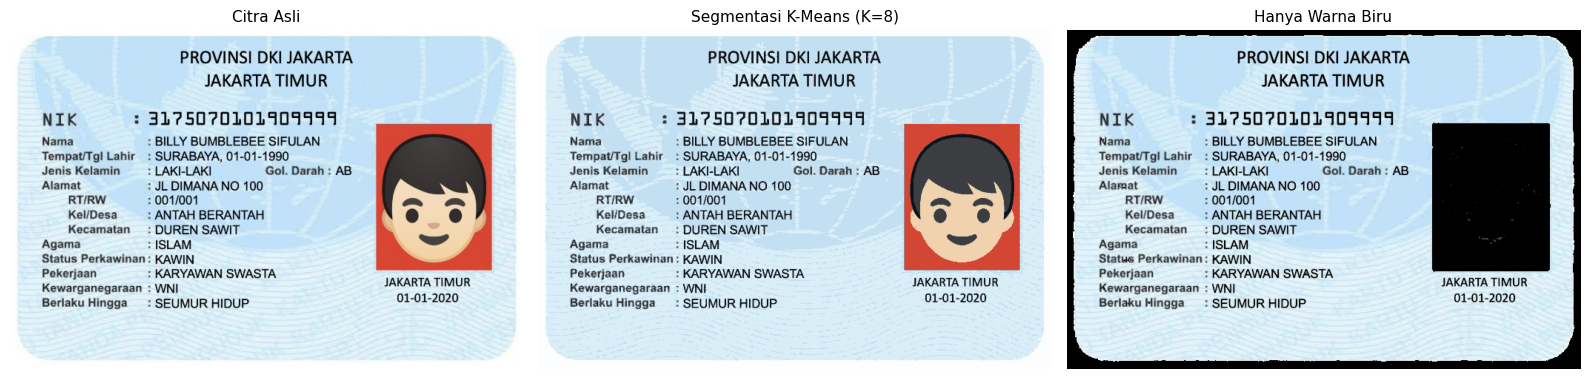

In [18]:
K = 8

# --- Pendekatan 1: kuantisasi warna dengan K-Means ---
ktp_rgb = bgr2rgb(ktp_bgr)
Z = np.float32(ktp_rgb.reshape(-1, 3))          # tiap piksel menjadi satu baris fitur RGB

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(Z)

pusat = np.uint8(kmeans.cluster_centers_)
terkuantisasi = pusat[kmeans.labels_].reshape(ktp_rgb.shape)

jumlah_anggota = np.bincount(kmeans.labels_, minlength=K)
print(f'K = {K} | inertia (WCSS) = {kmeans.inertia_:.0f}')
print('Pusat cluster (R, G, B) dan jumlah piksel anggotanya:')
for i, warna in enumerate(pusat):
    print(f'  cluster {i}: RGB {tuple(int(v) for v in warna)} -> {jumlah_anggota[i]:6d} piksel '
          f'({100 * jumlah_anggota[i] / Z.shape[0]:5.1f}%)')

# --- Pendekatan 2: pemisahan warna biru di ruang HSV ---
hsv = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2HSV)
H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]

# Ambang S diturunkan dari 25 (nilai pada modul) karena ktp.jpeg sudah
# terkompresi JPEG sehingga saturasi latar birunya lebih rendah. Dengan
# S = 25 sebagian piksel latar ikut terbuang dan label teks di sisi kiri
# berubah menjadi bintik hitam.
kelompok_biru = (H >= 85) & (H <= 130) & (S >= 10) & (V >= 40)

hanya_biru = np.zeros_like(ktp_rgb)
hanya_biru[kelompok_biru] = ktp_rgb[kelompok_biru]

print(f'\nPiksel kelompok biru: {kelompok_biru.sum()} '
      f'({100 * kelompok_biru.mean():.1f}% dari {kelompok_biru.size} piksel)')

tampilkan_citra(
    [ktp_rgb, terkuantisasi, hanya_biru],
    ['Citra Asli', f'Segmentasi K-Means (K={K})', 'Hanya Warna Biru'],
    figsize=(16, 5),
)

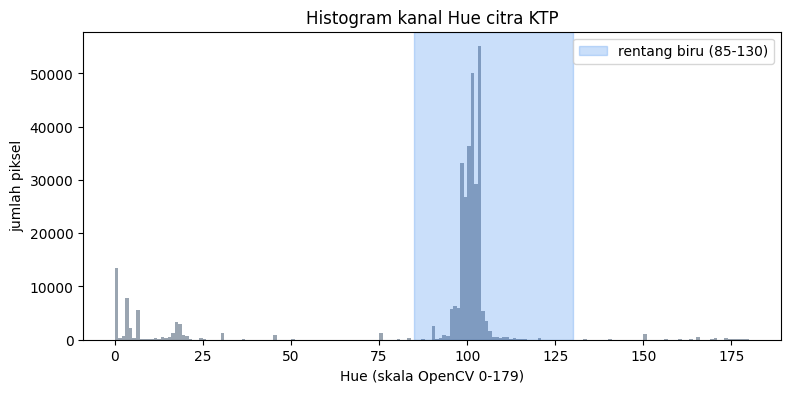

Nilai tengah Hue pada area latar : 103
Nilai tengah Hue pada area foto  : 16


In [19]:
# Histogram kanal Hue untuk melihat di mana puncak warna citra berada
plt.figure(figsize=(9, 4))
plt.hist(H.ravel(), bins=180, range=(0, 180), color='#9aa5b1')
plt.axvspan(85, 130, color='#2f80ed', alpha=0.25, label='rentang biru (85-130)')
plt.title('Histogram kanal Hue citra KTP')
plt.xlabel('Hue (skala OpenCV 0-179)')
plt.ylabel('jumlah piksel')
plt.legend()
plt.show()

# Nilai tengah Hue pada area latar dan pada area foto sebagai pembanding
print(f'Nilai tengah Hue pada area latar : {np.median(H[20:60, 300:600]):.0f}')
print(f'Nilai tengah Hue pada area foto  : {np.median(H[150:280, 520:640]):.0f}')

**Pembacaan hasil.**

- **Panel K-Means (K = 8)** memperlihatkan citra yang hanya tersusun atas 8
  warna. Dari daftar pusat cluster terlihat bahwa kelompok warna pada KTP
  memang terpisah dengan jelas: ada cluster untuk latar biru muda, cluster untuk
  putih, cluster untuk hitam teks, dan cluster untuk warna kulit serta latar
  foto. K-Means bekerja baik di sini karena warna KTP memang terbagi dalam
  kelompok yang tidak saling tumpang tindih. Perlu dicatat bahwa K-Means
  mengelompokkan piksel hanya berdasarkan warna tanpa mempertimbangkan letaknya,
  sehingga region hasilnya tidak dijamin terhubung — misalnya satu cluster bisa
  muncul di beberapa tempat berbeda pada citra.
- **Panel "Hanya Warna Biru"** menunjukkan hasil pemisahan di ruang HSV. Latar
  biru muda KTP berhasil dipertahankan, sedangkan piksel di luar rentang warna
  tersebut dijadikan hitam. Karena latar biru di sekitar tulisan tetap
  dipertahankan, tulisan hitam justru tetap terbaca sebagai teks gelap di atas
  latar biru.

Histogram Hue menegaskan mengapa rentang 85–130 cocok: puncak terbesar
histogram berada tepat di dalam rentang tersebut, yaitu pada latar biru KTP.
Pemisahan berdasarkan Hue juga lebih tahan terhadap perbedaan pencahayaan
daripada pemisahan di ruang RGB, karena informasi kecerahan sudah dipisahkan ke
kanal `V`.

Satu penyesuaian dilakukan pada ambang saturasi. Modul memakai `S >= 25`,
sedangkan berkas `ktp.jpeg` yang dipakai di sini sudah terkompresi JPEG
sehingga saturasi latar birunya lebih rendah. Dengan `S >= 25` sebagian piksel
latar yang saturasinya turun ikut terbuang, dan label teks di sisi kiri berubah
menjadi bintik hitam. Menurunkan ambang menjadi `S >= 10` mengembalikan latar
biru sekaligus mempertahankan teks, sementara rentang Hue 85-130 tetap seperti
ketentuan pada modul.

---

## D2. Tugas Kelompok — Konversi Gambar KTP Menjadi Teks (OCR)

OCR (*Optical Character Recognition*) adalah teknologi untuk mengenali tulisan
pada gambar dan mengubahnya menjadi teks digital yang dapat disalin, diedit,
atau diolah lebih lanjut. Tesseract berperan sebagai mesin OCR, sedangkan
`pytesseract` dipakai untuk mengaksesnya dari Python. Ketepatan pembacaan
dipengaruhi oleh kejelasan tulisan, pencahayaan, ukuran huruf, dan latar
belakang gambar.

Tujuannya adalah membandingkan pembacaan teks pada tiga citra masukan yang
berbeda perlakuan:

| Citra masukan | Perlakuan |
|---------------|-----------|
| Berwarna asli | tidak diubah, langsung dibaca |
| Segmentasi Otsu | grayscale, lalu threshold Otsu manual (bagian 3) |
| Segmentasi Adaptive | grayscale, lalu threshold adaptif Gaussian manual (bagian 2) |

Agar perbandingannya adil, ketiga citra memakai ukuran yang sama, bahasa yang
sama (`ind`), dan pengaturan `--psm` yang sama. Untuk segmentasi adaptif dipakai
jendela `11 × 11` dengan `C = 10`. Nilai `C` yang lebih besar daripada percobaan
pada citra sudoku diperlukan karena latar KTP sangat terang dan seragam; tanpa
`C` yang memadai, fluktuasi kecil pada latar sudah cukup untuk memunculkan
bintik-bintik yang mengganggu pembacaan.

### 6.1 Pemasangan Tesseract dan Model Bahasa Indonesia

Tesseract dipasang bersama model bahasa Indonesia (`tesseract-ocr-ind`) melalui
APT, sedangkan `pytesseract` dipasang sebagai pustaka Python. Perintah di bawah
berjalan pada Google Colab.

In [20]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [21]:
import pytesseract
from pytesseract import Output

LANG = 'ind'        # model bahasa Indonesia
PSM = '--psm 6'     # asumsi satu blok teks yang seragam

print('Versi Tesseract :', pytesseract.get_tesseract_version())
print('Bahasa tersedia :', pytesseract.get_languages(config=''))

Versi Tesseract : 5.3.4
Bahasa tersedia : ['eng', 'ind', 'osd']


### 6.2 Menyiapkan Tiga Citra yang Dibandingkan

Citra KTP dihaluskan lebih dulu, kemudian diubah menjadi grayscale. Dari citra
yang sama, dua versi segmentasi dibentuk: satu dengan Otsu manual dan satu dengan
threshold adaptif Gaussian manual. Keduanya memakai fungsi yang sudah dibangun
dan diverifikasi pada bagian 2 dan 3, sehingga tidak ada implementasi baru yang
perlu dipercaya begitu saja.

Otsu pada KTP            : v = 165
Adaptive Gaussian        : blok 11x11, C = 10, sigma = 2
Piksel putih (Otsu)      : 84.4%
Piksel putih (Adaptive)  : 91.8%


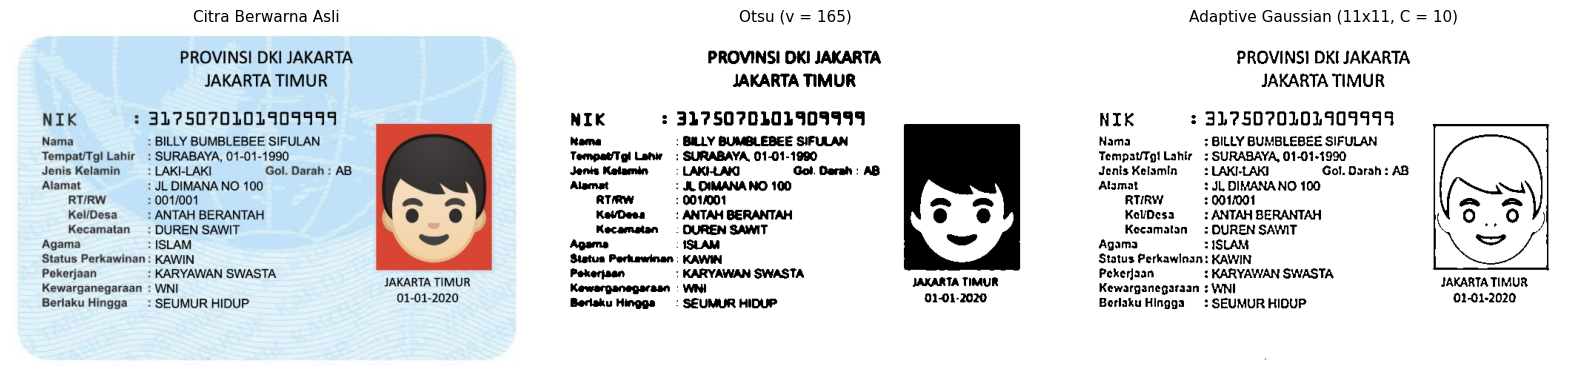

In [22]:
ktp_ocr_gray = cv.GaussianBlur(ke_gray(ktp_bgr), (5, 5), 0)

t_otsu_ktp_ocr = otsu_manual(ktp_ocr_gray)
ktp_otsu    = threshold_manual(ktp_ocr_gray, t_otsu_ktp_ocr, 'BINARY')
ktp_adaptif = adaptive_manual(ktp_ocr_gray, 'gaussian', blok=11, C=10)

ktp_asli_ocr = bgr2rgb(ktp_bgr)

print(f'Otsu pada KTP            : v = {t_otsu_ktp_ocr}')
print(f'Adaptive Gaussian        : blok 11x11, C = 10, sigma = 2')
print(f'Piksel putih (Otsu)      : {100 * (ktp_otsu > 0).mean():.1f}%')
print(f'Piksel putih (Adaptive)  : {100 * (ktp_adaptif > 0).mean():.1f}%')

tampilkan_citra(
    [ktp_asli_ocr, ktp_otsu, ktp_adaptif],
    ['Citra Berwarna Asli',
     f'Otsu (v = {t_otsu_ktp_ocr})',
     'Adaptive Gaussian (11x11, C = 10)'],
    cmap=[None, 'gray', 'gray'], figsize=(16, 5),
)

### 6.3 Pembacaan Teks dan Perbandingan Hasil

`pytesseract.image_to_string()` mengembalikan teks hasil pembacaan. Sebagai
acuan penilaian dipilih 10 kata atau angka yang terlihat jelas pada citra KTP.
Sebuah item dihitung **cocok** bila seluruh huruf atau angkanya terbaca sama
dengan acuan, dengan mengabaikan perbedaan huruf besar-kecil serta spasi di
awal dan akhir. Perbandingan dilakukan setelah teks dinormalkan (huruf kecil,
tanpa spasi dan tanda baca) supaya perbedaan format penulisan tidak ikut
terhitung sebagai kesalahan pembacaan.

Daftar `acuan` di bawah berisi item dari citra KTP contoh pada folder aset.
Untuk tugas kelompok, daftar ini diganti dengan 10 item dari KTP masing-masing
anggota.

In [23]:
def baca_teks(citra):
    """Membaca teks pada citra dengan bahasa dan psm yang seragam."""
    return pytesseract.image_to_string(citra, lang=LANG, config=PSM)


def normalisasi(teks):
    """Huruf kecil tanpa spasi/tanda baca, agar perbandingan tidak sensitif
    terhadap huruf besar-kecil dan spasi."""
    return ''.join(karakter for karakter in teks.lower() if karakter.isalnum())


def rata_confidence(citra):
    """Rata-rata confidence seluruh kata yang dikenali pada citra."""
    data = pytesseract.image_to_data(citra, lang=LANG, config=PSM, output_type=Output.DICT)
    nilai = []
    for c in data['conf']:
        try:
            c = float(c)
        except (TypeError, ValueError):
            continue
        if c >= 0:
            nilai.append(c)
    return float(np.mean(nilai)) if nilai else 0.0


# 10 item acuan yang terlihat jelas pada citra KTP
acuan = [
    '3175070101909999',          # NIK
    'BILLY BUMBLEBEE SIFULAN',   # nama
    'SURABAYA',                  # tempat lahir
    '01-01-1990',                # tanggal lahir
    'LAKI-LAKI',                 # jenis kelamin
    'AB',                        # golongan darah
    'JL DIMANA NO 100',          # alamat
    'ANTAH BERANTAH',            # kelurahan
    'DUREN SAWIT',               # kecamatan
    'SEUMUR HIDUP',              # masa berlaku
]

masukan = {'Berwarna': ktp_asli_ocr, 'Otsu': ktp_otsu, 'Adaptive': ktp_adaptif}
teks_ocr = {nama: baca_teks(citra) for nama, citra in masukan.items()}

for nama, teks in teks_ocr.items():
    print('=' * 25, nama)
    print(teks.strip())
    print()

========================= Berwarna
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

========================= Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?507D101909919
kama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahu: SURABAYA, 01-01-1900
Jenis Kelamin: LAKI-LAKI Gol, Darah : AB
Alamat : JL DIMANA NO 100

RT Rw : 0017001

KevDesa —: ANTAH BERANTAH d z )

Kecamatan: DUREN SAWIT
Status Perkawinan : KAWIN
Pekerjaan aan 8 KARYAWAN SWASTA TA TIMUR
Berlaku Hingga —: SEUMUR HIDUP 01-01-2020

========================= Adaptive
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK 3 31?50?20101901999
Nama 1 BILLY BUMBLEBEE SIFULAN
Tempat/T

In [24]:
# Tabel perbandingan per item acuan
baris = []
for item in acuan:
    baris.append({
        'Teks sebenarnya': item,
        **{nama: ('cocok' if normalisasi(item) in normalisasi(teks_ocr[nama]) else 'tidak cocok')
           for nama in masukan},
    })

tabel_perbandingan = pd.DataFrame(baris, index=range(1, len(acuan) + 1))
tabel_perbandingan.index.name = 'No.'
tabel_perbandingan

,Teks sebenarnya,Berwarna,Otsu,Adaptive
No.,,,,
1,3175070101909999,tidak cocok,tidak cocok,tidak cocok
2,BILLY BUMBLEBEE SIFULAN,cocok,cocok,cocok
3,SURABAYA,cocok,cocok,cocok
4,01-01-1990,cocok,tidak cocok,cocok
5,LAKI-LAKI,cocok,cocok,cocok
6,AB,cocok,cocok,cocok
7,JL DIMANA NO 100,cocok,cocok,cocok
8,ANTAH BERANTAH,cocok,cocok,cocok
9,DUREN SAWIT,cocok,cocok,cocok


In [25]:
# Ringkasan kecocokan dan rata-rata confidence tiap citra masukan
ringkasan = []
for nama, citra in masukan.items():
    tepat = sum(1 for item in acuan if normalisasi(item) in normalisasi(teks_ocr[nama]))
    ringkasan.append({
        'Citra masukan OCR': nama,
        'Item terbaca tepat': f'{tepat} dari {len(acuan)}',
        'Kecocokan (%)': round(100 * tepat / len(acuan), 1),
        'Rata-rata confidence': round(rata_confidence(citra), 1),
    })

pd.DataFrame(ringkasan)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna,9 dari 10,90.0,81.2
1,Otsu,8 dari 10,80.0,73.4
2,Adaptive,9 dari 10,90.0,65.0


### 6.4 Menampilkan Area Teks yang Dikenali

`pytesseract.image_to_data()` mengembalikan koordinat setiap kata beserta nilai
*confidence*-nya. Kotak hijau digambar hanya pada kata dengan confidence di atas
60, sehingga bagian citra yang benar-benar dikenali mesin OCR dapat dilihat
langsung. Batas confidence dibuat sama untuk ketiga citra agar perbandingannya
konsisten.

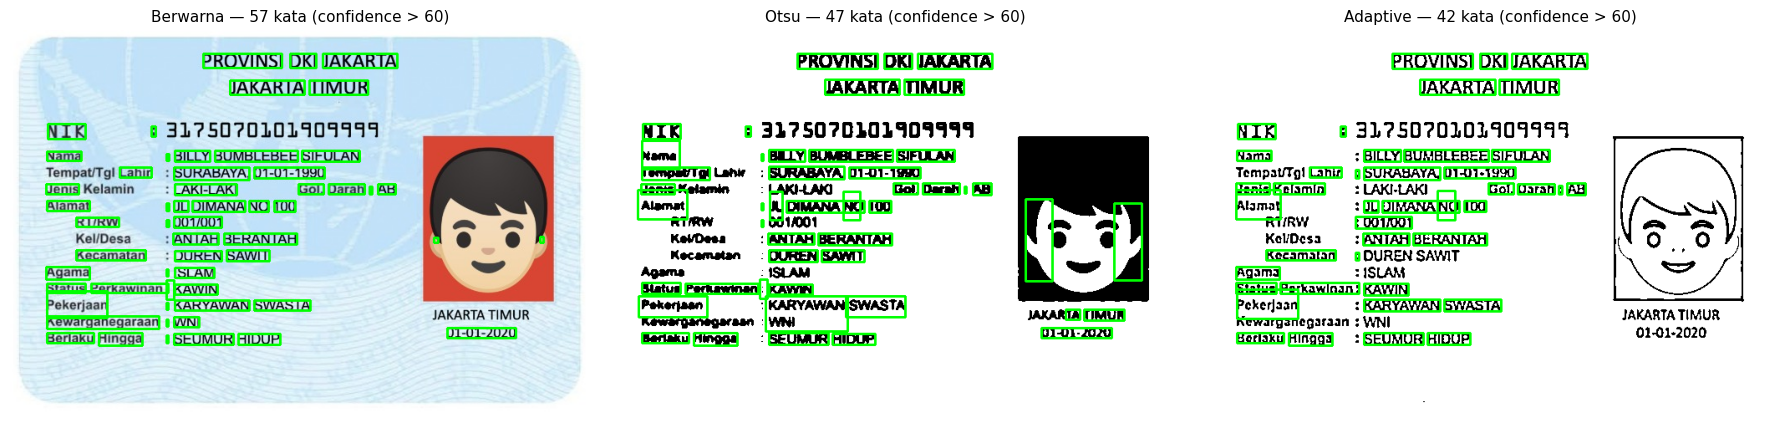

In [26]:
def tandai_kotak(citra, batas_confidence=60):
    """Menggambar kotak hijau pada kata yang dikenali dengan confidence di atas batas.

    Citra masukan sudah berformat RGB, sehingga hasilnya dikembalikan apa adanya.
    Memanggil bgr2rgb() di sini justru menukar kanal merah dan biru, sehingga latar
    biru KTP tampil kecoklatan dan area foto tampil biru.
    """
    keluaran = citra.copy()
    if keluaran.ndim == 2:
        keluaran = cv.cvtColor(keluaran, cv.COLOR_GRAY2BGR)

    data = pytesseract.image_to_data(citra, lang=LANG, config=PSM, output_type=Output.DICT)

    jumlah = 0
    for i, teks in enumerate(data['text']):
        try:
            confidence = float(data['conf'][i])
        except (TypeError, ValueError):
            continue
        if confidence > batas_confidence and teks.strip():
            x, y = data['left'][i], data['top'][i]
            w, h = data['width'][i], data['height'][i]
            cv.rectangle(keluaran, (x, y), (x + w, y + h), (0, 255, 0), 2)
            jumlah += 1

    return keluaran, jumlah


hasil_kotak = [tandai_kotak(citra) for citra in masukan.values()]

tampilkan_citra(
    [gambar for gambar, _ in hasil_kotak],
    [f'{nama} — {jumlah} kata (confidence > 60)'
     for nama, (_, jumlah) in zip(masukan, hasil_kotak)],
    figsize=(18, 5),
)

### 6.5 Hasil dan Analisis

Hasil yang diperoleh dari citra KTP contoh pada folder aset (10 item acuan,
`lang = ind`, `--psm 6`, batas confidence 60) adalah sebagai berikut.

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence |
|-------------------|--------------------|---------------|----------------------|
| Berwarna asli | 9 dari 10 | 90,0 | 79,2 |
| Segmentasi Otsu | 8 dari 10 | 80,0 | 74,4 |
| Segmentasi Adaptive | 9 dari 10 | 90,0 | 71,6 |

**1. Citra masukan mana yang menghasilkan pembacaan paling tepat?**

Citra **berwarna asli**. Pembacaannya tepat pada 9 dari 10 item acuan (90%),
nilainya setara dengan citra adaptive, tetapi rata-rata confidence-nya paling
tinggi (79,2). Buktinya terlihat pada tabel perbandingan: citra berwarna
berhasil membaca tanggal `01-01-1990` dengan benar, sedangkan segmentasi Otsu
salah membacanya menjadi `01-01-1900`. Segmentasi Otsu juga hanya mencapai 8
dari 10 item, paling rendah di antara ketiganya.

**2. Minimal dua kesalahan pembacaan.**

- **NIK salah baca pada ketiga citra.** Angka `3175070101909999` terbaca
  menjadi `31?5020101401911` pada citra berwarna, `32?507D101909999` pada citra
  Otsu, dan `3)75D70101909993` pada citra adaptive. Deretan angka panjang tanpa
  pemisah adalah kasus tersulit bagi OCR karena satu karakter yang salah
  merusak seluruh item.
- **Tanggal lahir salah pada citra Otsu.** `01-01-1990` terbaca menjadi
  `01-01-1900`; angka 9 tertukar menjadi 0 setelah segmentasi.
- **Label ikut salah baca.** Pada citra Otsu, label `Nama` terbaca menjadi
  `kama` dan `Tempat/Tgl Lahir` menjadi `Tempat/Tgi Lahu`. Pada citra adaptive,
  label `NIK` terbaca `NIK` tetapi diikuti pemisah yang salah (`NIK:` bukan
  `NIK :`).

**3. Apakah segmentasi selalu meningkatkan ketepatan OCR?**

**Tidak.** Pada percobaan ini segmentasi Otsu justru **menurunkan** kecocokan
dari 90% menjadi 80% dan confidence dari 79,2 menjadi 74,4. Segmentasi adaptif
menyamai citra berwarna pada jumlah item yang tepat (90%), tetapi dengan
confidence yang lebih rendah (71,6).

Penyebabnya adalah segmentasi membuang informasi keabuan dan hanya menyisakan
dua nilai. Pada citra KTP yang resolusinya kecil, goresan huruf menjadi tipis
dan sebagian huruf yang saling menempel ikut terpisah atau justru menyatu.
Otsu yang memakai satu ambang untuk seluruh citra juga terpaksa mengorbankan
salah satu area: nilai ambang yang tepat untuk teks di bagian terang membuat
teks di area yang lebih gelap ikut hilang, dan sebaliknya.

**4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**

Latar KTP berwarna biru muda dengan pola *watermark* tipis. Pola tersebut
memiliki intensitas yang mirip dengan goresan huruf tipis, sehingga setelah
thresholding sebagian pola ikut terbaca sebagai garis atau bintik yang
mengganggu. Selain itu, bagian KTP yang memuat foto memiliki latar merah dengan
kecerahan jauh berbeda dari latar biru. Satu ambang global tidak dapat
menangani kedua area tersebut sekaligus, sehingga pada citra hasil Otsu area
foto berubah menjadi blok hitam pekat. Sebaliknya, pada citra berwarna asli
Tesseract masih dapat memisahkan teks hitam dari latar biru berdasarkan
perbedaan kecerahan, sehingga pembacaannya lebih baik.

**5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki
kecocokan tertinggi?**

**Tidak selalu berbanding lurus.** Pada percobaan ini citra Otsu memiliki
confidence lebih tinggi daripada citra adaptive (74,4 berbanding 71,6), tetapi
kecocokannya justru lebih rendah (80% berbanding 90%). Sebaliknya, citra
adaptive menyamai citra berwarna pada kecocokan (90%), walaupun confidence-nya
jauh lebih rendah (71,6 berbanding 79,2).

Hal ini masuk akal karena kedua ukuran mengukur hal yang berbeda. *Confidence*
menilai seberapa yakin mesin OCR terhadap apa yang dibacanya, sedangkan
kecocokan menilai apakah hasilnya benar-benar sama dengan tulisan pada gambar.
Mesin dapat sangat yakin pada pembacaan yang salah — misalnya yakin bahwa angka
`9` adalah `0` — sehingga confidence yang tinggi tidak menjamin ketepatan.
Karena itu penilaian pada tugas ini mengacu pada kecocokan item, bukan pada
nilai confidence saja.